# 12 · Serving a tagging method

A frozen tagging method answers HTTP requests here: MLflow's own model server serves it, in one
Docker image per method that runs on local Docker, Kubernetes and SageMaker, on the CPU or the
GPU as the deployment says ([ADR 0012](../docs/adr/0012-serving-tagging-methods.md)). The method
served is `f2llm_late_fusion`, the late fusion of [notebook 09](09_f2llm.ipynb), and the notebook
follows one problem from a client to the method and back.

Sections 4 to 9 serve live: they package the method from its committed folder, serve it on this
machine's CPU, and ask it about test-set problems and a typed one. Sections 10 to 12 quote
recorded runs (the Docker images, compose, a kind cluster, SageMaker's container contract), each
with its command and its date, from [`docs/serving-runs.md`](../docs/serving-runs.md).
The test-set problems are a demonstration: each live answer is compared with the frozen test row
of the same method, and the notebook computes no metric and chooses nothing
([ADR 0001](../docs/adr/0001-model-selection-protocol.md)).

**Contents**
1. What we deploy
2. MLflow serving at a glance
3. Our architecture
4. The MLflow model, from code
5. The signature
6. Serve locally
7. Predict
8. Stop the server
9. The container
10. Docker and compose (recorded)
11. Kubernetes (recorded)
12. SageMaker (recorded)
13. The Streamlit client
14. Next steps

In [1]:
import warnings

# mlflow imports tqdm, which warns in a notebook that it cannot draw its progress bars as widgets
# (ipywidgets is not installed): this notebook draws none.
warnings.filterwarnings("ignore", message="IProgress not found")

In [2]:
import json
import subprocess
import sys
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from codeforces_tags.cli_methods import CliError
from codeforces_tags.config import (
    CLI_DEFAULT_METHOD,
    FOCUS_TAGS,
    PROJECT_ROOT,
    SERVING_BUILD_DIR,
)
from codeforces_tags.evaluation.timing import latency_summary, load_latency
from codeforces_tags.methods import METHODS, method_dir
from codeforces_tags.serving.client import ServingError, ping, predict, request_payload
from codeforces_tags.serving.local import (
    server_environment,
    start_local_server,
    stop,
    wait_for_ping,
)
from codeforces_tags.serving.mlflow_links import method_links, mlflow_ui_url, ui_alive
from codeforces_tags.serving.package import run_command, served_signature
from codeforces_tags.serving.problems import (
    frozen_prediction,
    live_differences,
    load_test_set,
    problem_from_form,
    tag_table,
)

METHOD = "f2llm_late_fusion"  # the tagging method served here
spec = METHODS[METHOD]
pd.set_option("display.max_colwidth", None)  # the tables show whole paths and links

## 1. What we deploy

`f2llm_late_fusion` is a score method: it fuses the standardised scores of two scorers, the
frozen TF-IDF model of [notebook 04](04_tfidf_baseline.ipynb) and a linear probe on F2LLM-0.6B's
frozen embeddings of the statement and the solution, and predicts a focus tag when the fused score
reaches the tag's per-tag threshold, cross-fitted on the dev set. It calls no API, and the
encoder's weights (1.2 GB) are pinned by hash in its method folder. The command line's default
stays `jev-statement-code` ([ADR 0008](../docs/adr/0008-cli-default-method.md)), a method that
calls an API: a model server can serve it too, one problem per request, but the method served
here runs offline and for free. The table reads the registry and the frozen timings of one
problem per call, on the GPU (`latency.csv`) and on the CPU (`analysis/cpu/latency.csv`).

In [3]:
gpu_latency = load_latency(method_dir(METHOD))
cpu_latency = load_latency(method_dir(METHOD) / "analysis" / "cpu")
gpu, cpu = latency_summary(gpu_latency.seconds), latency_summary(cpu_latency.seconds)
pd.Series(
    {
        "kind": spec.kind,
        "calls an API": spec.calls_api,
        "dependency groups": ", ".join(spec.groups),
        "score_atol": spec.score_atol,
        "GPU: load, s": round(gpu_latency.load_s, 2),
        "GPU: median per problem, s": round(gpu["median_s"], 3),
        "GPU: slowest problem, s": round(gpu["max_s"], 3),
        "CPU: load, s": round(cpu_latency.load_s, 2),
        "CPU: median per problem, s": round(cpu["median_s"], 3),
        "CPU: slowest problem, s": round(cpu["max_s"], 3),
        "default method of the command line": CLI_DEFAULT_METHOD,
    },
    name=METHOD,
).to_frame()

,f2llm_late_fusion
kind,score
calls an API,False
dependency groups,f2llm
score_atol,0.00009
"GPU: load, s",8.84
"GPU: median per problem, s",0.138
"GPU: slowest problem, s",0.245
"CPU: load, s",7.81
"CPU: median per problem, s",3.033
"CPU: slowest problem, s",8.484


**What it shows.** A problem takes a fraction of a second on the GPU and a few seconds on the
CPU, under the 10-second budget of `PROBLEM.md` on both. These are the method's own frozen
timings (`tracking latency`, one problem per call, inside one Python process), not a model
server's. The model server's round trips are measured below: on the CPU in sections 7 and 10,
and on the GPU in section 10, under compose's `gpu` profile. Loading the method takes longer (the imports of torch and transformers, and
the hashing of the weights), which is why every platform below waits until `/ping` answers before
it sends a request.

## 2. MLflow serving at a glance

MLflow serves any model saved in its format with one scoring server: `mlflow models serve` runs
it on this machine, `mlflow models build-docker` puts it in an image whose entrypoint starts it,
and deployment platforms such as SageMaker and Kubernetes run that image. The figure is MLflow's
own overview of these paths ([MLflow 3.16.1's documentation](https://mlflow.org/docs/3.16.1/ml/deployment/),
Apache-2.0; `figures/mlflow_docs/README.md` names the source of each of its figures). One label of
it is out of date: the scoring server is no longer a Flask application. In MLflow 3.16.1 it is a
FastAPI application served by uvicorn, behind nginx inside a container, and the image of this
notebook runs exactly that.

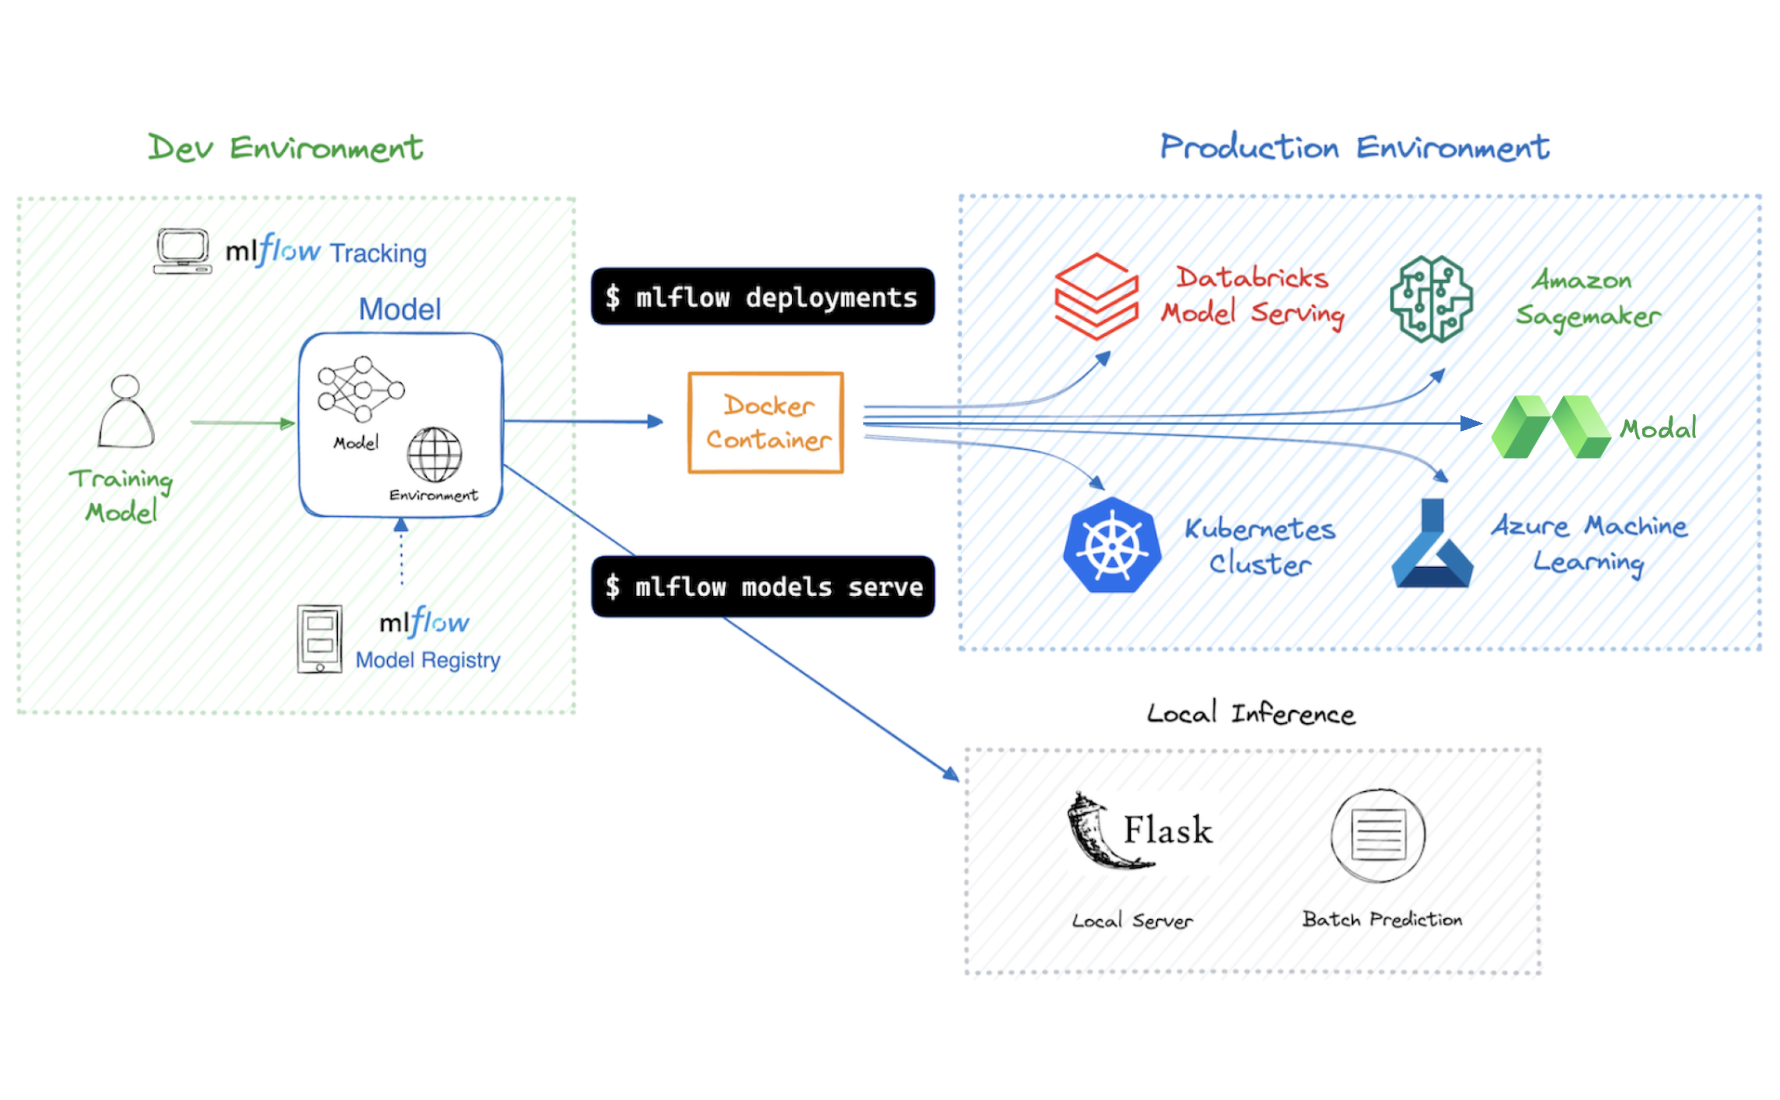

In [4]:
Image(filename="figures/mlflow_docs/mlflow-deployment-overview.png", width=760)

## 3. Our architecture

The served model is built from the committed method folder, never from the MLflow store, so any
checkout that holds the folder and the weight caches builds it again. `python -m
codeforces_tags.serving package` turns `assets/methods/f2llm_late_fusion/model` into a Docker
build context in `build/serving/f2llm_late_fusion/`: an MLflow model, the weights the folder pins,
the exact pins of `uv.lock` and the Dockerfile. `serving build` makes one image of it, which every
platform runs, and `serving.local` serves the same MLflow model on this machine without Docker.
Every client (the Streamlit app, `serving smoke`, this notebook) speaks to the model server
through `serving/client.py`; the app also links the served method to what MLflow tracked about it,
in the MLflow UI.

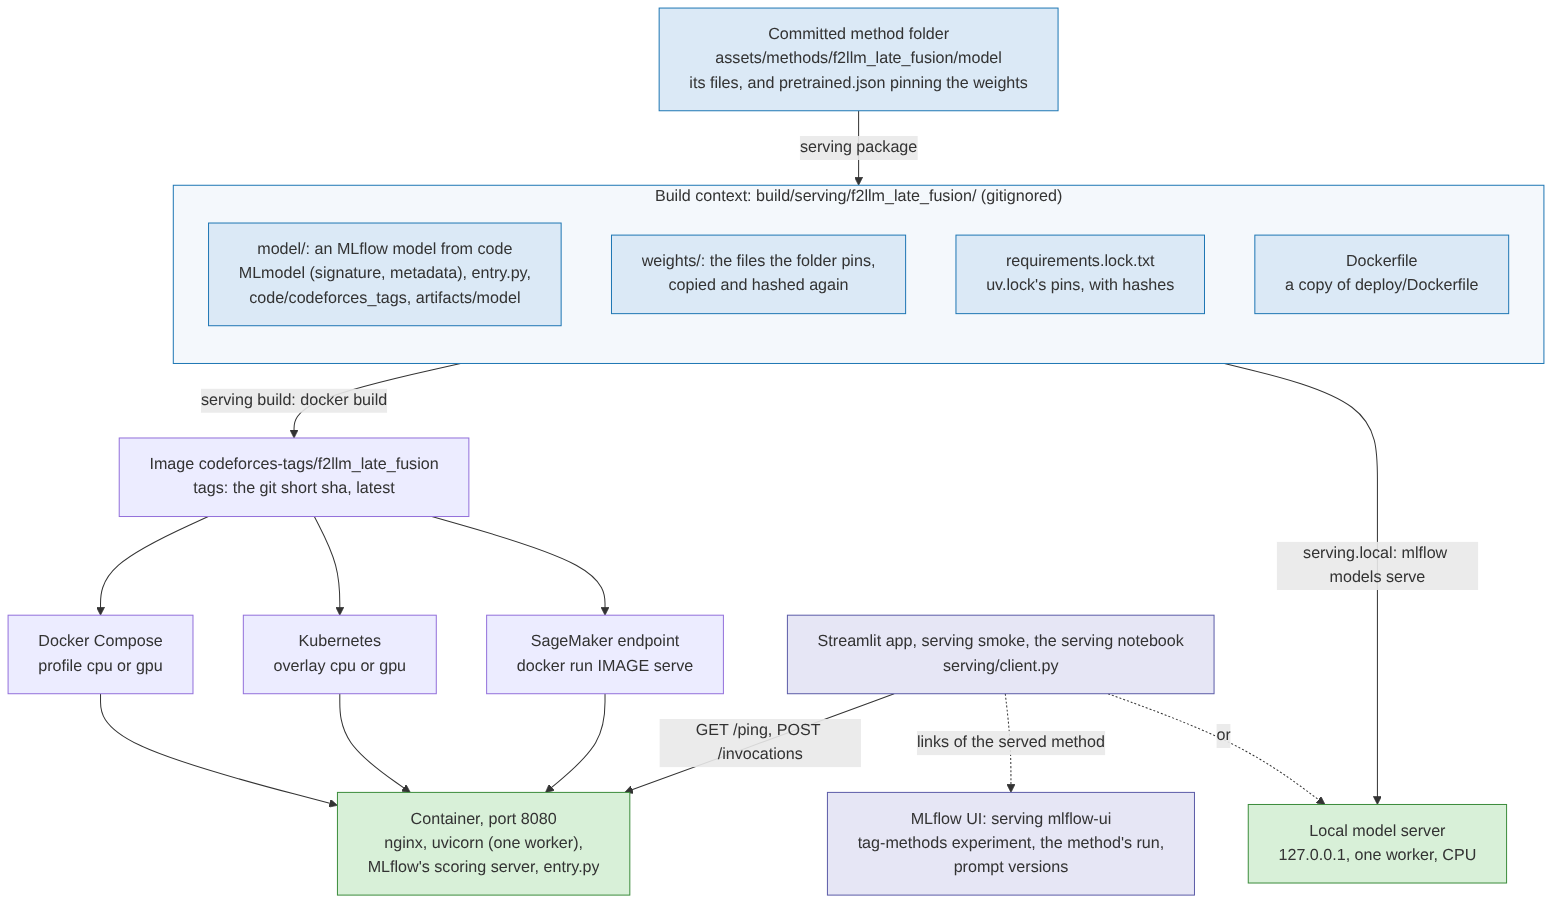

In [5]:
Image(filename="figures/serving_architecture.png", width=900)

## 4. The MLflow model, from code

MLflow saves a model either as a serialised Python object or from code: a script that builds the
model and ends with `mlflow.models.set_model`, which MLflow copies into the model and runs when it
loads it (the figure, from MLflow's documentation). The project saves from code only, since a
serialised object is a pickle (CLAUDE.md, No pickle). The entry file is
`src/codeforces_tags/serving/entry.py`: its `ServedMethodModel` loads the method folder, carried as
the artifact `method`, with `load_method`, and answers each request with `served_records`, the
command line's own `run_method` written as one record per problem.

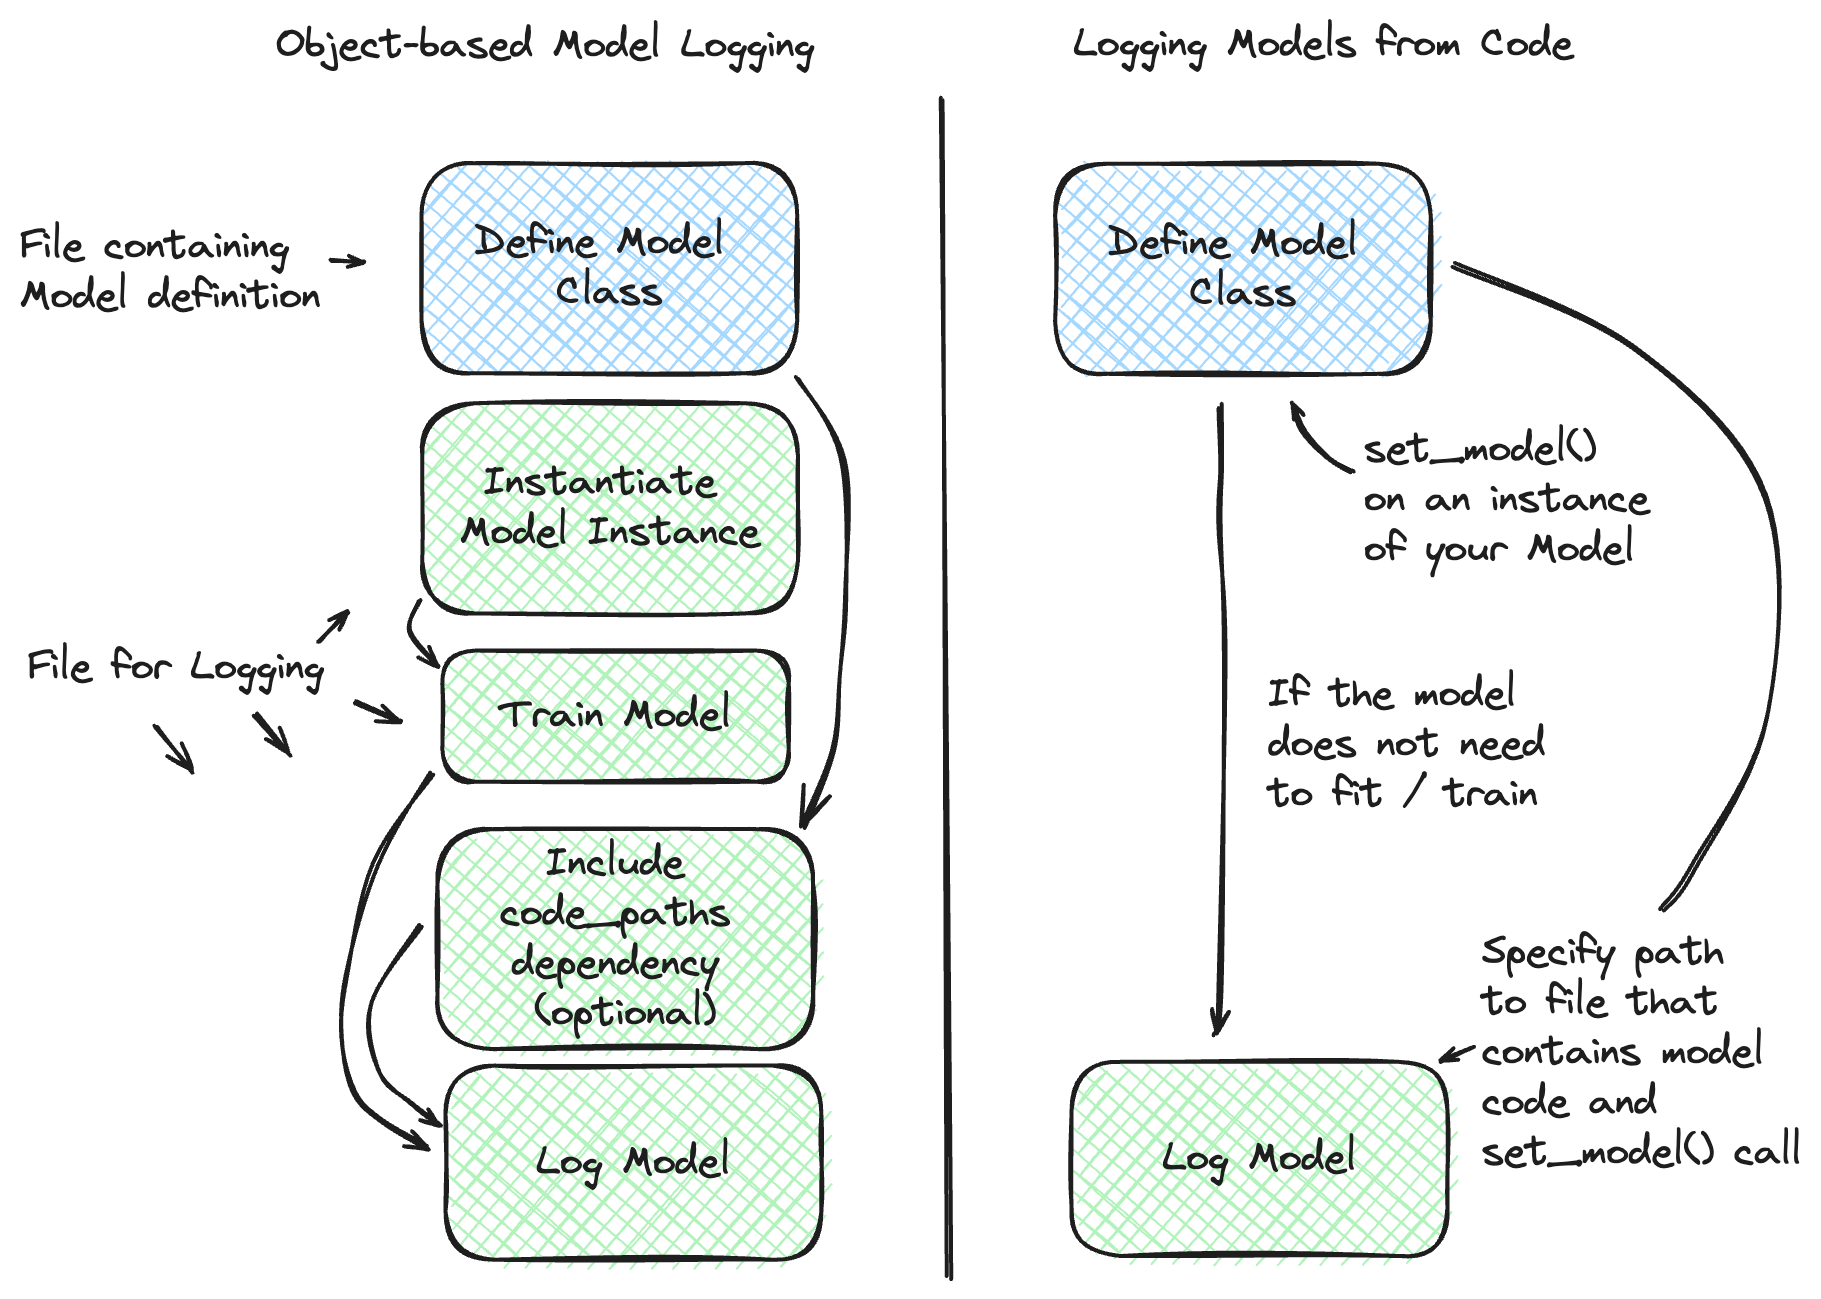

In [6]:
Image(filename="figures/mlflow_docs/models_from_code.png", width=760)

The cell runs the command, `python -m codeforces_tags.serving package --method
f2llm_late_fusion`. It refuses, before it writes anything, a method that is not frozen, whose
weights are missing from their caches, or whose code, Dockerfile or method folder differs from
the last commit; then it writes the build context afresh. Below the command's line is that
context, with the files of `model/code` (the package `codeforces_tags`, which MLflow puts on
`sys.path` when it loads the model) and of `model/artifacts` (the method folder) counted rather
than listed.

In [7]:
command = [sys.executable, "-m", "codeforces_tags.serving", "package", "--method", METHOD]
build = SERVING_BUILD_DIR / METHOD
# build/serving may be a link to another disk: its paths are shown as the repository's.
real_build = str(build.resolve())
try:
    output = run_command(command)
except subprocess.CalledProcessError as error:
    raise RuntimeError(f"serving package failed:\n{error.stderr}") from error
print(output.replace(real_build, str(build)).replace(str(PROJECT_ROOT), "<repo>"))
print(f"{build.relative_to(PROJECT_ROOT)}/")
for path in sorted(build.rglob("*")):
    parts = path.relative_to(build).parts
    if parts[:2] in (("model", "code"), ("model", "artifacts")) and len(parts) > 2:
        continue  # counted below
    size = f"  {path.stat().st_size:,} bytes" if path.is_file() else "/"
    print(f"{'    ' * len(parts)}{parts[-1]}{size}")
counts = {
    folder: sum(path.is_file() for path in (build / "model" / folder).rglob("*"))
    for folder in ("code", "artifacts")
}
print(f"model/code holds {counts['code']} files, model/artifacts {counts['artifacts']}")

packaged f2llm_late_fusion in <repo>/build/serving/f2llm_late_fusion

build/serving/f2llm_late_fusion/
    Dockerfile  1,213 bytes
    model/
        MLmodel  3,069 bytes
        artifacts/
        code/
        conda.yaml  354 bytes
        entry.py  4,256 bytes
        python_env.yaml  107 bytes
        requirements.txt  216 bytes
    requirements.lock.txt  233,148 bytes
    weights/
        pretrained/
            codefuse-ai--F2LLM-0.6B/
                eb2778d335980b42b986c75d7fe3a78be19ef3a6/
                    1_Pooling/
                        config.json  298 bytes
                    added_tokens.json  707 bytes
                    config.json  722 bytes
                    config_sentence_transformers.json  216 bytes
                    merges.txt  1,671,853 bytes
                    model.safetensors  1,192,133,232 bytes
                    modules.json  350 bytes
                    special_tokens_map.json  613 bytes
                    tokenizer.json  11,423,195 bytes
  

In [8]:
mlmodel = (build / "model" / "MLmodel").read_text(encoding="utf-8")
print(mlmodel.replace(str(PROJECT_ROOT), "<repo>"))

flavors:
  python_function:
    artifacts:
      method:
        path: artifacts/model
        uri: <repo>/assets/methods/f2llm_late_fusion/model
    cloudpickle_version: 3.1.2
    code: code
    env:
      conda: conda.yaml
      virtualenv: python_env.yaml
    loader_module: mlflow.pyfunc.loaders.code_model
    model_code_path: <repo>/src/codeforces_tags/serving/entry.py
    python_version: 3.12.12
    streamable: false
is_signature_from_type_hint: false
metadata:
  code_dirty: false
  git_commit: 027e45eeac5e38140ec5d48d6672cb886b280064
  method: f2llm_late_fusion
mlflow_version: 3.16.1
model_id: null
model_size_bytes: 4162827
model_uuid: 438562c771744f209f81d66e27d75931
prompts: null
signature:
  inputs: '[{"type": "string", "name": "prob_desc_description", "required": true},
    {"type": "string", "name": "prob_desc_input_spec", "required": true}, {"type":
    "string", "name": "prob_desc_output_spec", "required": true}, {"type": "string",
    "name": "prob_desc_notes", "required"

In [9]:
print((build / "model" / "requirements.txt").read_text(encoding="utf-8"))
lock = (build / "requirements.lock.txt").read_text(encoding="utf-8").splitlines()
pins = [line.split(" ")[0] for line in lock if "==" in line and not line.startswith("#")]
print(f"requirements.lock.txt pins {len(pins)} packages for the image, each with its hashes:")
print(", ".join(pins[:8]), "...")

iterative-stratification==0.1.9
jinja2==3.1.6
numpy==2.5.3
pandas==3.0.6
pyyaml==6.0.3
scikit-learn==1.9.1
scipy==1.18.1
skops==0.16.0
peft==0.21.2
safetensors==0.8.0
torch==2.14.1
transformers==5.19.0
mlflow==3.16.1
requirements.lock.txt pins 140 packages for the image, each with its hashes:
accelerate==1.15.0, aiohappyeyeballs==2.7.1, aiohttp==3.14.4, aiosignal==1.4.0, alembic==1.20.0, annotated-doc==0.0.5, annotated-types==0.8.0, anyio==4.15.1 ...


**What it shows.** `MLmodel` names the loader `mlflow.pyfunc.loaders.code_model` (a model from
code), the entry file, the artifact `method`, the signature of section 5 and the metadata
(`method`, `git_commit`, `code_dirty`). Its `cloudpickle_version` line is one MLflow writes for
any Python model; nothing here is pickled: the model holds no `python_model.pkl`, and the loader
runs `entry.py`. `requirements.txt` pins the project's dependencies, the method's and mlflow to
the versions `uv.lock` pins, and no `uv.lock` or `pyproject.toml` was copied into the model:
`package_method` sets MLflow's environment first. `requirements.lock.txt` is what the image
installs, every package of its dependency groups at `uv.lock`'s version with its hashes, so that
`pip install --require-hashes` refuses any other file.

## 5. The signature

MLflow checks every request against the model's signature before the model sees it (the figure,
from MLflow's documentation): a missing input column, or a value of another type, is refused with
a 400 and never reaches the method. The inputs are the raw columns the method reads, all strings
(the sample inputs and outputs as the JSON text of a list, a field the problem lacks as null). The
outputs are the served record: the method's name, one 0/1 column per focus tag and, for a score
method, each focus tag's score and per-tag threshold (`inf` for a tag the method never
predicts).

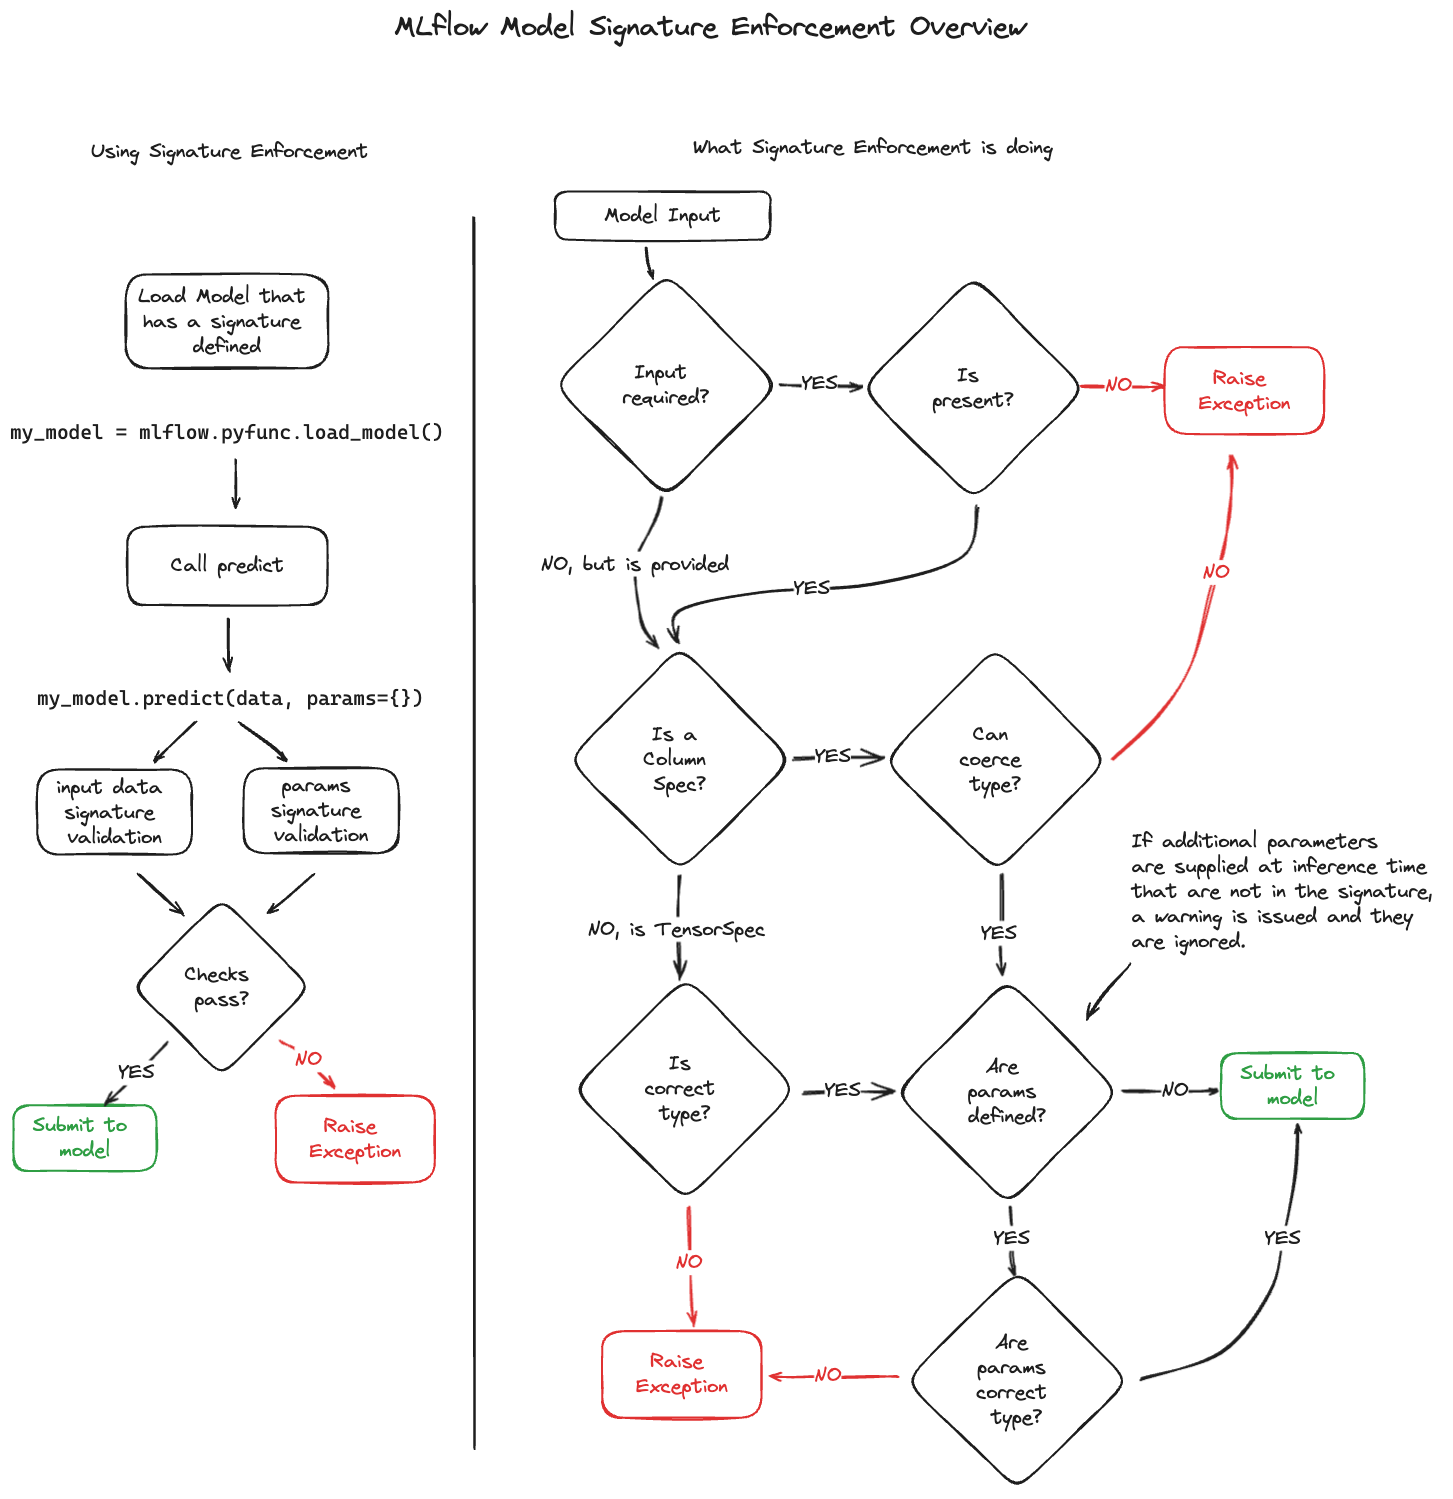

In [10]:
Image(filename="figures/mlflow_docs/signature-enforcement.png", width=760)

In [11]:
signature = served_signature(spec)
display(pd.DataFrame(signature.inputs.to_dict()).set_index("name"))
pd.DataFrame(signature.outputs.to_dict()).set_index("name")

,type,required
name,,
prob_desc_description,string,True
prob_desc_input_spec,string,True
prob_desc_output_spec,string,True
prob_desc_notes,string,True
prob_desc_sample_inputs,string,True
prob_desc_sample_outputs,string,True
source_code,string,True


,type,required
name,,
method,string,True
math,long,True
graphs,long,True
strings,long,True
number theory,long,True
trees,long,True
geometry,long,True
games,long,True
probabilities,long,True


## 6. Serve locally

`serving.local` runs MLflow's own command line, `mlflow models serve`, on the packaged model: the
scoring server that the image runs, without nginx and without Docker, on a free port of 127.0.0.1
with one worker. Its environment is the image's: the CPU (`CODEFORCES_DEVICE=cpu`), the weights
staged in the build context, no download, no bytecode written into `model/code`, and MLflow's
safeguards (no pickle loaded, no telemetry). Its standard input is `/dev/null`: `mlflow models
serve` starts uvicorn through `bash -c`, which, given a socket for stdin, would read `~/.bashrc`.
The table lists the variables it adds to this environment (`PATH` aside).

In [12]:
model_dir = build / "model"
added = server_environment(model_dir, "cpu", base={})
pd.Series(
    {
        name: value.replace(real_build, str(build)).replace(str(PROJECT_ROOT), "<repo>")
        for name, value in added.items()
        if name != "PATH"
    },
    name="value",
).rename_axis("variable").to_frame()

,value
variable,
MLFLOW_ALLOW_PICKLE_DESERIALIZATION,false
MLFLOW_UV_AUTO_DETECT,false
MLFLOW_LOG_UV_FILES,false
MLFLOW_GENAI_EVAL_MAX_WORKERS,1
MLFLOW_ENABLE_ASYNC_TRACE_LOGGING,false
MLFLOW_MODEL_CATALOG_URI,
MLFLOW_DISABLE_AGENT_HINT,1
MLFLOW_SERVER_ENABLE_JOB_EXECUTION,false
MLFLOW_DISABLE_TELEMETRY,true


In [13]:
server = start_local_server(model_dir, device="cpu")
wait_for_ping(server)
log = build / server.log.relative_to(build.resolve())  # the log, seen through build/serving
print(f"{METHOD} answers {server.url}/ping; its log is {log.relative_to(PROJECT_ROOT)}")

f2llm_late_fusion answers http://127.0.0.1:53309/ping; its log is build/serving/f2llm_late_fusion/server.log


A request crosses the scoring server as below: MLflow reads the frame and checks it against the
signature, then the entry file takes a lock, so that one prediction (on a GPU, one forward pass)
runs at a time, and answers one record per problem. In the container, nginx answers 502 until the
method has loaded, and `/ping` answers 200 only then.

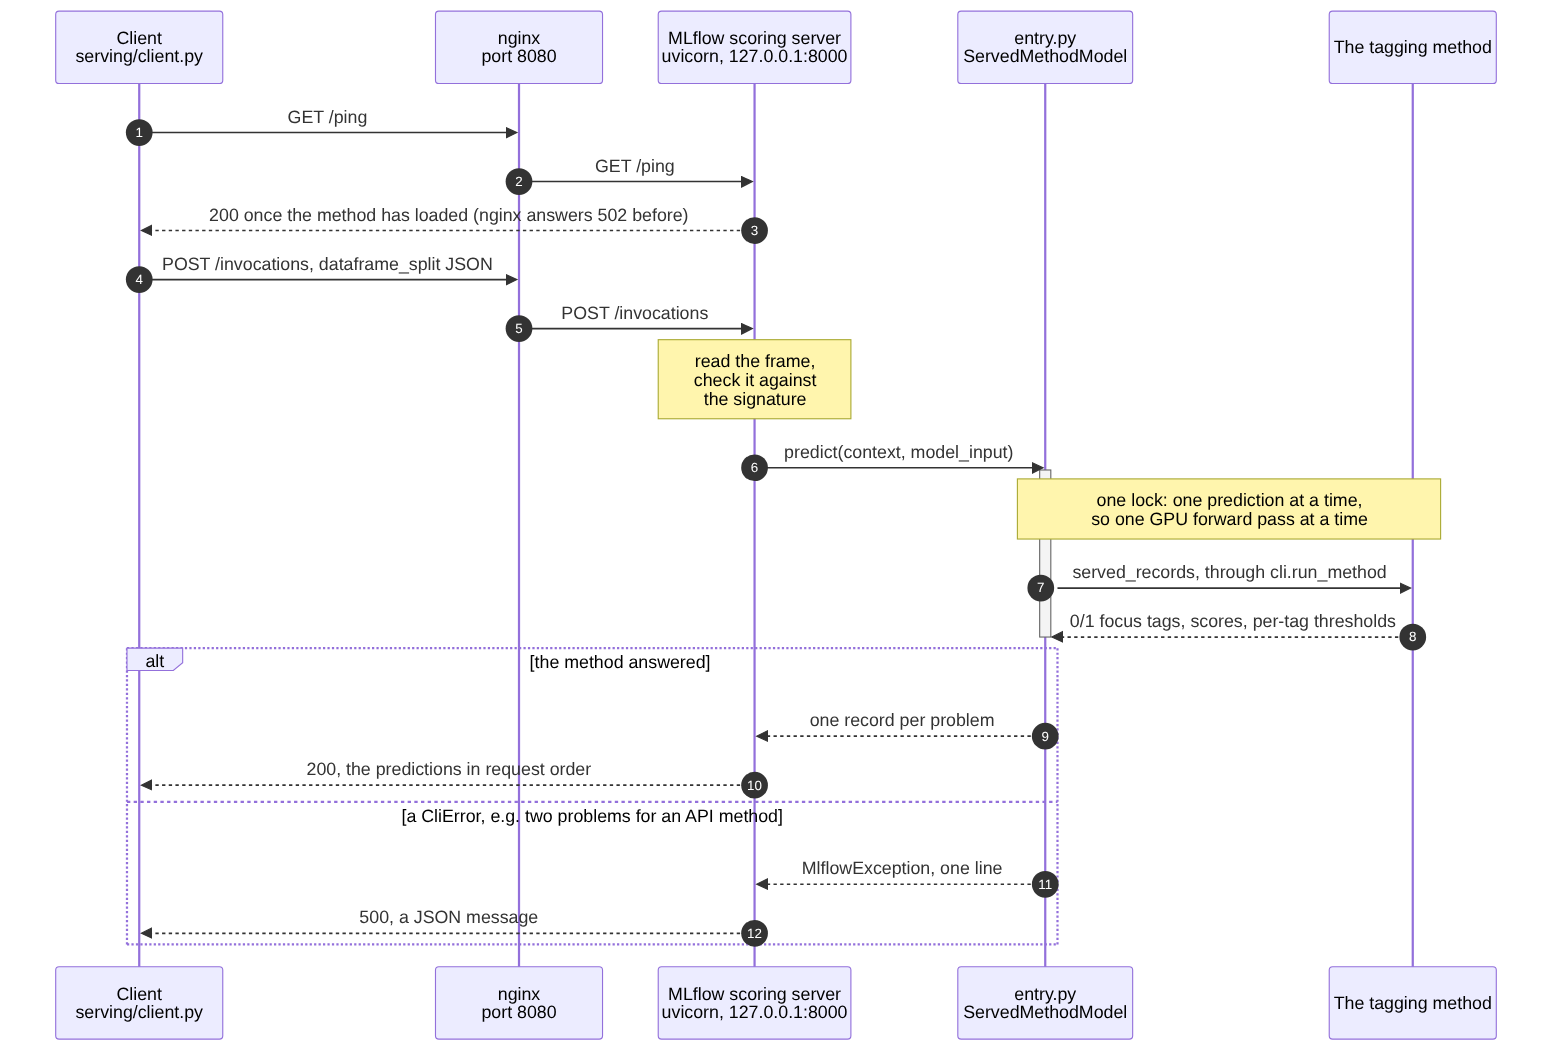

In [14]:
Image(filename="figures/serving_request.png", width=900)

## 7. Predict

Three test-set problems, the first three of the test set in its order, chosen by nothing else.
Each is sent alone, as `serving smoke` sends them, and its answer is compared with the frozen test
row of `f2llm_late_fusion` by the rule of `verify`'s level (a): each score within `score_atol` of
the frozen one, and a focus tag flipped only where the frozen score lies within `score_atol` of
its per-tag threshold (the frozen scores were computed on the GPU, these on the CPU). The cell
fails on any other difference. First, the body of the first request: every raw input column,
`null` for a field the problem lacks, the sample inputs and outputs as the JSON text of a list
(each value cut at 90 characters here).

In [15]:
problems, truth = load_test_set()
chosen = list(problems.index[:3])
payload = request_payload(problems.loc[chosen[:1]])["dataframe_split"]
for column, value in zip(payload["columns"], payload["data"][0], strict=True):
    print(f"{column}: {json.dumps(value)[:90]}")

prob_desc_description: "Bear Limak has n colored balls, arranged in one long row. Balls are numbered 1 through n,
prob_desc_input_spec: "The first line of the input contains a single integer n (1\u2009\u2264\u2009n\u2009\u2264
prob_desc_output_spec: "Print n integers. The i-th of them should be equal to the number of intervals where i is 
prob_desc_notes: "NoteIn the first sample, color 2 is dominant in three intervals:  An interval [2,\u20092]
prob_desc_sample_inputs: "[\"4\\n1 2 1 2\", \"3\\n1 1 1\"]"
prob_desc_sample_outputs: "[\"7 3 0 0\", \"6 0 0\"]"
source_code: "N = int(5e3+3)\nn = int(input())\nres = [0] * N\ncum = list([0] * N for _ in range(N))\na


In [16]:
answers = {sample_id: predict(server.url, problems.loc[[sample_id]])[0] for sample_id in chosen}
rows = {}
for sample_id, answer in answers.items():
    frozen = frozen_prediction(METHOD, sample_id)
    differences = live_differences(answer, frozen, score_atol=spec.score_atol)
    assert not differences, differences
    rows[sample_id] = {
        "round trip, s": round(answer.seconds, 2),
        "predicted": ", ".join(answer.tags) or "none",
        "frozen": ", ".join(tag for tag in FOCUS_TAGS if frozen.tags[tag]) or "none",
        "true": ", ".join(tag for tag in FOCUS_TAGS if truth.at[sample_id, tag]) or "none",
    }
pd.DataFrame.from_dict(rows, orient="index").rename_axis("sample_id")

,"round trip, s",predicted,frozen,true
sample_id,,,,
13,7.14,none,none,none
14,2.13,geometry,geometry,strings
15,1.64,none,none,none


In [17]:
for sample_id, answer in answers.items():
    print(f"Problem {sample_id}")
    display(tag_table(answer, truth.loc[sample_id].to_dict(), frozen_prediction(METHOD, sample_id)))

Problem 13


,predicted,score,threshold,true,frozen,agrees
tag,,,,,,
math,0,-0.719025,0.193543,0,0,True
graphs,0,-0.715167,0.972482,0,0,True
strings,0,0.353130,1.393822,0,0,True
number theory,0,-0.175117,1.540741,0,0,True
trees,0,0.162778,1.561231,0,0,True
geometry,0,-0.618902,2.512351,0,0,True
games,0,-0.340825,3.646012,0,0,True
probabilities,0,-0.015186,3.462582,0,0,True


Problem 14


,predicted,score,threshold,true,frozen,agrees
tag,,,,,,
math,0,-0.313099,0.193543,0,0,True
graphs,0,0.113620,0.972482,0,0,True
strings,0,-0.216266,1.393822,1,0,True
number theory,0,1.369107,1.540741,0,0,True
trees,0,-0.591253,1.561231,0,0,True
geometry,1,3.856956,2.512351,0,1,True
games,0,-0.353123,3.646012,0,0,True
probabilities,0,-0.285109,3.462582,0,0,True


Problem 15


,predicted,score,threshold,true,frozen,agrees
tag,,,,,,
math,0,-0.345054,0.193543,0,0,True
graphs,0,-0.928813,0.972482,0,0,True
strings,0,-0.383468,1.393822,0,0,True
number theory,0,-0.080676,1.540741,0,0,True
trees,0,-0.276232,1.561231,0,0,True
geometry,0,0.239007,2.512351,0,0,True
games,0,-0.354838,3.646012,0,0,True
probabilities,0,-0.677559,3.462582,0,0,True


**What it shows.** The live answers match the frozen test rows by the rule of `verify`'s level
(a): the cell's assertion would have stopped the notebook otherwise. A problem takes a few seconds
on the CPU, as the frozen CPU timings of section 1 say (the round trip adds the HTTP request).
Whether a prediction is right (the column `true`) is shown, not counted: the test set was scored
once, when the method was frozen. The same comparison on the first 20 test-set problems, by
`serving smoke`, was recorded when the method was first served on this machine, with
`serving.local` on the CPU, while the machine was shared with other work: its median was 4.88 s,
and its slowest problem took 11.21 s, above the 10-second budget of `PROBLEM.md`. The model
server's latency on the CPU is the compose run of section 10: median 3.40 s, slowest 8.21 s,
under the budget. On the GPU, under compose's `gpu` profile, the same 20 problems took 0.148 s at
the median and 0.262 s at the slowest (section 10), beside the method's own frozen 0.14 s. The
record:

**Smoke: f2llm_late_fusion on a local server (CPU).** Run on 2026-10-11T21:32:42Z (UTC), exit status 0, in 115 s.

```console
$ uv run --offline python -m codeforces_tags.serving smoke --url http://127.0.0.1:8080 --method f2llm_late_fusion
problem 13: 3.759 s, no tag: agrees
problem 14: 3.870 s, geometry: agrees
problem 15: 3.357 s, no tag: agrees
problem 18: 6.308 s, no tag: agrees
problem 29: 5.045 s, graphs: agrees
problem 37: 4.775 s, math: agrees
problem 39: 3.694 s, no tag: agrees
problem 60: 9.198 s, strings: agrees
problem 62: 6.957 s, no tag: agrees
problem 64: 4.558 s, graphs: agrees
problem 68: 4.289 s, math: agrees
problem 69: 4.988 s, no tag: agrees
problem 71: 6.108 s, no tag: agrees
problem 74: 11.211 s, no tag: agrees
problem 75: 2.947 s, no tag: agrees
problem 79: 8.593 s, graphs: agrees
problem 89: 6.085 s, math: agrees
problem 95: 7.646 s, math, probabilities: agrees
problem 99: 3.244 s, no tag: agrees
problem 107: 2.302 s, strings, games: agrees
20 test problems, one request each: median 4.881 s, slowest 11.211 s; 0 differ from their frozen test rows
```

A problem typed into the Streamlit app's form goes through `problem_from_form` first: every text
as typed, a blank optional field as null, the sample pairs as two lists of texts. This one,
written for the notebook, asks for Euler's totient, a number-theory problem; it has no notes.

In [18]:
typed = problem_from_form(
    {
        "prob_desc_description": (
            "You are given an integer $$$n$$$. Count the integers $$$k$$$ with "
            "$$$1 \\le k \\le n$$$ such that $$$\\gcd(k, n) = 1$$$."
        ),
        "prob_desc_input_spec": (
            "The only line contains one integer $$$n$$$ ($$$1 \\le n \\le 10^{12}$$$)."
        ),
        "prob_desc_output_spec": "Print the number of such integers $$$k$$$.",
        "source_code": (
            "n = int(input())\n"
            "result, rest, p = n, n, 2\n"
            "while p * p <= rest:\n"
            "    if rest % p == 0:\n"
            "        while rest % p == 0:\n"
            "            rest //= p\n"
            "        result -= result // p\n"
            "    p += 1\n"
            "if rest > 1:\n"
            "    result -= result // rest\n"
            "print(result)\n"
        ),
    },
    [("12", "4"), ("7", "6")],
)
[typed_answer] = predict(server.url, typed)
tags = ", ".join(typed_answer.tags) or "no focus tag"
print(f"{typed_answer.method} in {typed_answer.seconds:.2f} s: {tags}")
tag_table(typed_answer)

f2llm_late_fusion in 0.88 s: math, number theory


,predicted,score,threshold,true,frozen,agrees
tag,,,,,,
math,1,1.203108,0.193543,<NA>,<NA>,<NA>
graphs,0,-0.286083,0.972482,<NA>,<NA>,<NA>
strings,0,0.101297,1.393822,<NA>,<NA>,<NA>
number theory,1,4.079862,1.540741,<NA>,<NA>,<NA>
trees,0,-0.438992,1.561231,<NA>,<NA>,<NA>
geometry,0,0.131579,2.512351,<NA>,<NA>,<NA>
games,0,-0.440681,3.646012,<NA>,<NA>,<NA>
probabilities,0,0.339620,3.462582,<NA>,<NA>,<NA>


A problem without a solution is refused by the client before anything is sent, with the command
line's own message (`cli.check_fields`): a model server never sees a request it could not read.

In [19]:
without_solution = problems.loc[chosen[:1]].assign(source_code=None)
try:
    predict(server.url, without_solution)
except CliError as error:
    print(f"refused before it was sent: {error}")
else:
    raise AssertionError("a problem without a solution was sent")

refused before it was sent: every sample needs a text in prob_desc_description and source_code, but source_code holds none in sample_13.json.


## 8. Stop the server

`stop` ends the server's process group: `mlflow models serve` and the uvicorn it started. A
client that asks a stopped server gets one `ServingError`, with no status since no answer came,
never a traceback; the Streamlit app shows it as one message.

In [20]:
stop(server)
print(f"{server.url}/ping answers: {ping(server.url)}")
try:
    predict(server.url, problems.loc[chosen[:1]])
except ServingError as error:
    print(f"status {error.status}: {error.message}")
else:
    raise AssertionError(f"{server.url} answered once stopped")

http://127.0.0.1:53309/ping answers: False
status None: no answer from the model server at http://127.0.0.1:53309/invocations: [Errno 111] Connection refused


## 9. The container

The image runs MLflow's own container entrypoint, the one `mlflow models build-docker` writes:
nginx on port 8080 in front of uvicorn on 127.0.0.1:8000, with one worker. Its layers go from the
least to the most often changed (the Python packages, then the weights, then the model), so that
a new build of the same method reuses the largest layer, the packages'.

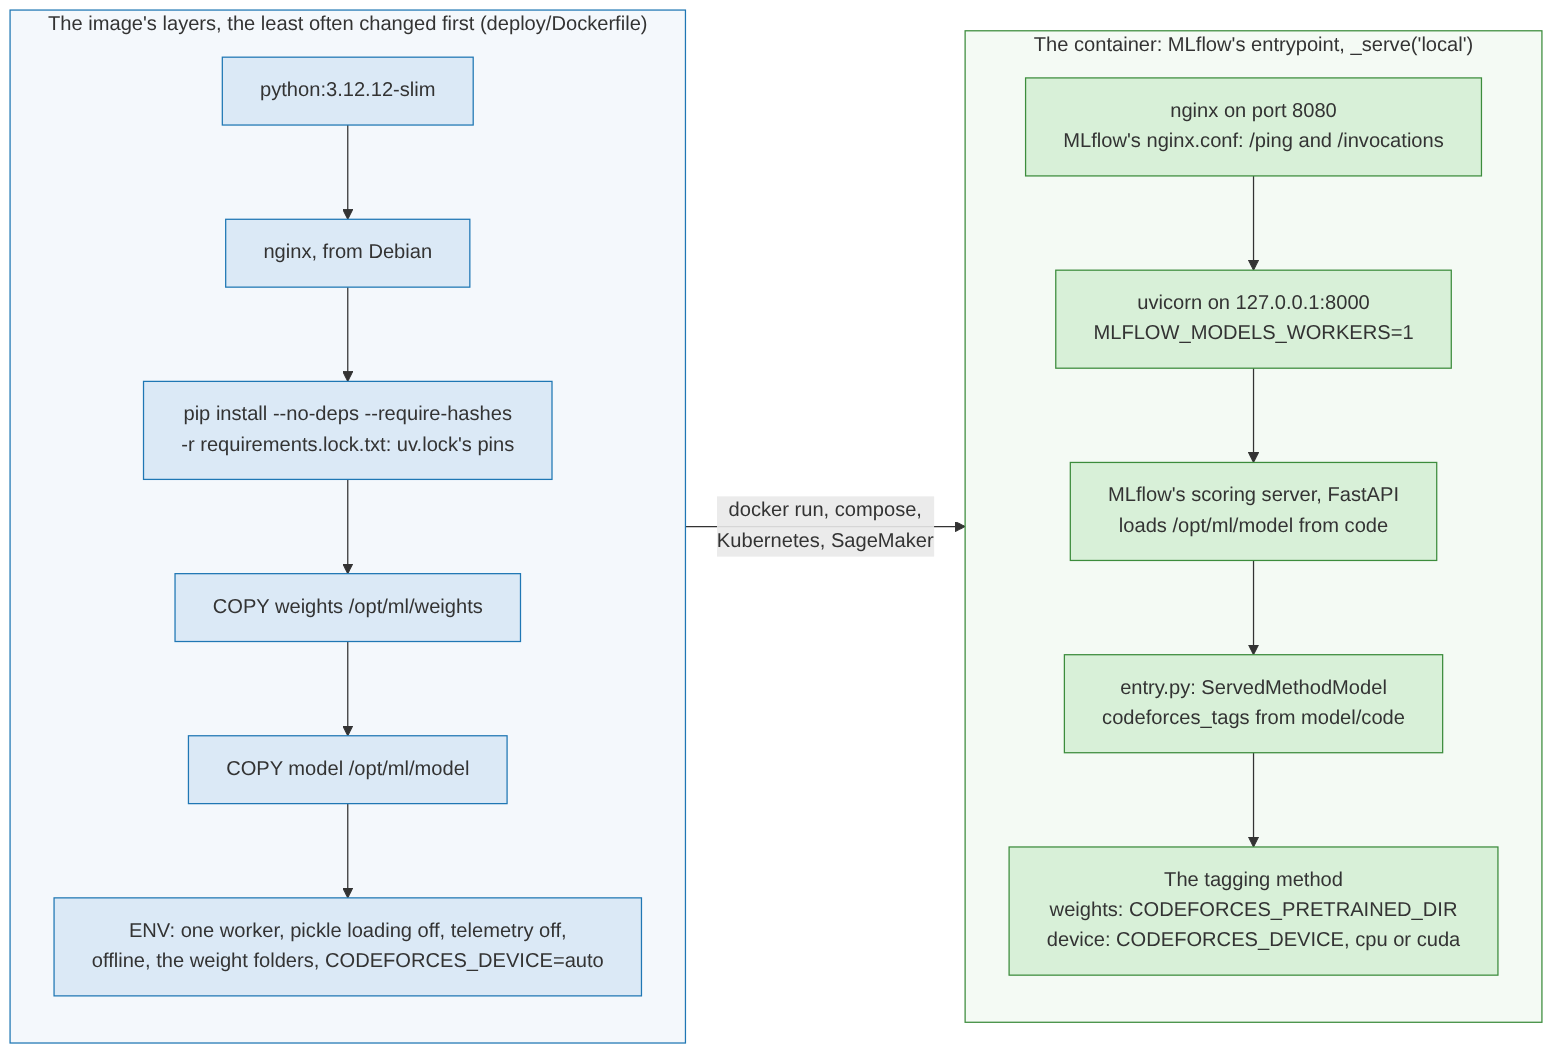

In [21]:
Image(filename="figures/serving_container.png", width=900)

MLflow writes its own Dockerfile for a model with `mlflow models generate-dockerfile
--env-manager local`. The cell writes it for the packaged model, beside ours (`deploy/Dockerfile`,
copied into the build context), and checks that both run the same entrypoint.

In [22]:
with tempfile.TemporaryDirectory() as folder:
    run_command(
        [
            sys.executable,
            "-m",
            "mlflow",
            "models",
            "generate-dockerfile",
            "-m",
            str(model_dir),
            "-d",
            folder,
            "--env-manager",
            "local",
        ]
    )
    generated = (Path(folder) / "Dockerfile").read_text(encoding="utf-8")
ours = (build / "Dockerfile").read_text(encoding="utf-8")
entrypoints = [
    [line for line in text.splitlines() if line.startswith("ENTRYPOINT")]
    for text in (ours, generated)
]
assert entrypoints[0] == entrypoints[1], entrypoints
print("Ours, deploy/Dockerfile:", ours, sep="\n")
print("MLflow's, generate-dockerfile --env-manager local:", generated, sep="\n")

Ours, deploy/Dockerfile:
FROM python:3.12.12-slim
ENV PYTHONDONTWRITEBYTECODE=1 PYTHONUNBUFFERED=1 PIP_NO_CACHE_DIR=1 PIP_DISABLE_PIP_VERSION_CHECK=1
RUN apt-get update && apt-get install -y --no-install-recommends nginx \
    && rm -rf /var/lib/apt/lists/*
COPY requirements.lock.txt /tmp/requirements.lock.txt
RUN pip install --no-deps --require-hashes -r /tmp/requirements.lock.txt \
    && rm /tmp/requirements.lock.txt
ARG METHOD
LABEL codeforces-tags.method=${METHOD}
COPY weights /opt/ml/weights
COPY model /opt/ml/model
ENV MLFLOW_MODELS_WORKERS=1 \
    MLFLOW_DISABLE_ENV_CREATION=True \
    MLFLOW_DISABLE_TELEMETRY=true \
    MLFLOW_ALLOW_PICKLE_DESERIALIZATION=false \
    MLFLOW_UV_AUTO_DETECT=false \
    MLFLOW_LOG_UV_FILES=false \
    MLFLOW_GENAI_EVAL_MAX_WORKERS=1 \
    MLFLOW_ENABLE_ASYNC_TRACE_LOGGING=false \
    MLFLOW_MODEL_CATALOG_URI= \
    MLFLOW_DISABLE_AGENT_HINT=1 \
    MLFLOW_SERVER_ENABLE_JOB_EXECUTION=false \
    HF_HUB_OFFLINE=1 \
    TRANSFORMERS_OFFLINE=1 \
    

**Difference by difference** (MLflow 3.16.1, which `uv.lock` pins):

| | MLflow's `generate-dockerfile` | Ours |
|---|---|---|
| Base image | `python:3.12.12-slim`, the version of the running interpreter | the same, written in the file |
| nginx | installed; the package lists removed in a later layer, so the first keeps them | installed, the package lists removed in the same layer |
| Python packages | `pip install mlflow==3.16.1`, then the model's `requirements.txt`, resolved by pip at build time, with gunicorn; pip's cache kept | `uv.lock`'s pins only (`requirements.lock.txt`), each with its hashes, `--no-deps`, no pip cache |
| Weights | none: the method would find no weights | `COPY weights /opt/ml/weights`, the files the method folder pins, before the model |
| Model | `COPY model_dir/model /opt/ml/model` | `COPY model /opt/ml/model` |
| Environment | `MLFLOW_DISABLE_ENV_CREATION=True` | the same, with one worker, pickle loading off, telemetry off, no uv files, Hugging Face offline, the weight folders and `CODEFORCES_DEVICE` |
| Work folder | `/opt/mlflow`, writable by all (for SageMaker Serverless) | none: SageMaker Serverless has no GPU and is not a target |
| Label | none | `codeforces-tags.method`, which `serving clean-images` filters on |
| Entrypoint | `_serve('local')`: nginx, then uvicorn | the same line (checked above, and by `tests/test_deploy_files.py`) |

## 10. Docker and compose (recorded)

`python -m codeforces_tags.serving build --method f2llm_late_fusion` packages the method, builds
`codeforces-tags/f2llm_late_fusion:<git short sha>` and `:latest`, then removes the method's
older images, BuildKit's cached build contexts (every one on the host, not only this method's:
they are caches, and a build sends its context again) and the staged weights. A second build of
`tfidf` shows that clean-up. `deploy/docker-compose.yml` runs the image under the profile `cpu`
or `gpu`, published on 127.0.0.1:8080 only, with a healthcheck on `/ping`, and `serving smoke`
compares 20 answers with the frozen test rows. Each record names its command and its date, and
the records are in the order they ran. They were taken with helper scripts of the gitignored
folder `experiments/serving-runs/` (`record.sh`, and `download_sizes.py`, which the first record
runs), which the end of `docs/serving-runs.md` describes (The helper scripts).

Both images were built at commit `1029973`: `codeforces-tags/tfidf` weighs 906 MB and
`codeforces-tags/f2llm_late_fusion` 7.89 GB (built in 188 s). The first build of `tfidf` made the
image `ce22ca2389c9`; the second made `8af058113b18` and removed the first, so `8af058113b18` is
the only image labelled `codeforces-tags.method=tfidf` after it (the last record of this section
lists the images). Under the profile `cpu`, the late-fusion container was healthy after 17 s, and
its 20 answers all agree with the frozen test rows (median 3.40 s, slowest 8.21 s).

The profile `gpu` ran about four hours later, on 2026-10-12 (UTC), once the NVIDIA Container
Toolkit 1.20.1 was installed, so its records come last. It served the image
`codeforces-tags/f2llm_late_fusion:324fcda`, built at a later commit of the private development
history. The container was healthy after 16 s, and its server's process held 2,432 MiB of GPU
memory. One problem first (0.366 s, the
first request of a fresh server), then the 20: they all agree with the frozen test rows (median
0.148 s, slowest 0.262 s, against 3.40 s and 8.21 s on the CPU). A watchdog sampled the GPU every
250 ms, ready to stop the container at 78 °C or after 10 s above 230 W. Sent back to back, the 20
requests drew 136 to 252 W for about 3 s and warmed the GPU to 56 °C: three samples passed 230 W,
never for 10 s in a row. The watchdog's script is the last record of the Docker part of
`docs/serving-runs.md`.

**What each build downloads from PyPI (sizes from uv.lock).** Run on 2026-10-11T22:25:04Z (UTC), exit status 0, in 0 s.

```console
$ uv run --offline python experiments/serving-runs/download_sizes.py --requirements build/serving/tfidf/requirements.lock.txt --top 3 && uv run --offline python experiments/serving-runs/download_sizes.py --requirements build/serving/f2llm_late_fusion/requirements.lock.txt --top 5
pyarrow==25.0.1: 50.1 MB
scipy==1.18.1: 35.3 MB
numpy==2.5.3: 16.7 MB
88 packages, 187.7 MB to download (sizes from uv.lock)
torch==2.14.1: 554.6 MB
nvidia-cudnn-cu13==9.24.0.43: 553.1 MB
nvidia-cublas==13.1.1.3: 423.1 MB
triton==3.8.0: 248.0 MB
nvidia-nccl-cu13==2.30.7: 216.0 MB
132 packages, 3223.8 MB to download (sizes from uv.lock)
```

**Build tfidf again: build removes the image it replaces.** Run on 2026-10-11T22:26:22Z (UTC), exit status 0, in 5 s.

```console
$ uv run --offline python -m codeforces_tags.serving build --method tfidf
[2 MLflow warnings and 5 progress-bar lines left out; the whole record is in docs/serving-runs.md]
packaged tfidf in <repo>/build/serving/tfidf
python -m codeforces_tags.serving: note: building codeforces-tags/tfidf:1029973: its log is printed only if the build fails
built codeforces-tags/tfidf:1029973 and codeforces-tags/tfidf:latest: image 8af058113b18, 0.91 GB
kept codeforces-tags/tfidf:1029973, codeforces-tags/tfidf:latest (image 8af058113b18)
pruned the dangling images labelled codeforces-tags.method=tfidf: Total reclaimed space: 0B
dropped BuildKit's cached build contexts: Total:	5.908MB
deleted the staged weights, which the image holds: <repo>/build/serving/tfidf/weights
```

**Build the f2llm_late_fusion image.** Run on 2026-10-11T22:26:41Z (UTC), exit status 0, in 188 s.

```console
$ uv run --offline --group f2llm python -m codeforces_tags.serving build --method f2llm_late_fusion
[2 MLflow warnings and 7 progress-bar lines left out; the whole record is in docs/serving-runs.md]
packaged f2llm_late_fusion in <repo>/build/serving/f2llm_late_fusion
python -m codeforces_tags.serving: note: building codeforces-tags/f2llm_late_fusion:1029973: its log is printed only if the build fails
built codeforces-tags/f2llm_late_fusion:1029973 and codeforces-tags/f2llm_late_fusion:latest: image 26be1c73ce3a, 7.89 GB
kept codeforces-tags/f2llm_late_fusion:1029973, codeforces-tags/f2llm_late_fusion:latest (image 26be1c73ce3a)
pruned the dangling images labelled codeforces-tags.method=f2llm_late_fusion: Total reclaimed space: 0B
dropped BuildKit's cached build contexts: Total:	1.214GB
deleted the staged weights, which the image holds: <repo>/build/serving/f2llm_late_fusion/weights
```

**The f2llm_late_fusion image and its layers.** Run on 2026-10-11T22:30:00Z (UTC), exit status 0, in 0 s.

```console
$ docker image ls codeforces-tags/f2llm_late_fusion --format 'table {{.Repository}}:{{.Tag}}\t{{.ID}}\t{{.Size}}' && docker history --no-trunc --format '{{.Size}}\t{{.CreatedBy}}' codeforces-tags/f2llm_late_fusion:latest | cut -c1-150 && df -h /
REPOSITORY:TAG                              IMAGE ID       SIZE
codeforces-tags/f2llm_late_fusion:1029973   26be1c73ce3a   7.89GB
codeforces-tags/f2llm_late_fusion:latest    26be1c73ce3a   7.89GB
0B	ENTRYPOINT ["python" "-c" "from mlflow.models import container as C; C._serve('local')"]
0B	EXPOSE map[8080/tcp:{}]
0B	ENV MLFLOW_MODELS_WORKERS=1 MLFLOW_DISABLE_ENV_CREATION=True MLFLOW_DISABLE_TELEMETRY=true MLFLOW_ALLOW_PICKLE_DESERIALIZATION=false MLFLOW_UV_AUTO
5.86MB	COPY model /opt/ml/model # buildkit
1.21GB	COPY weights /opt/ml/weights # buildkit
0B	LABEL codeforces-tags.method=f2llm_late_fusion
0B	ARG METHOD=f2llm_late_fusion
6.55GB	RUN /bin/sh -c pip install --no-deps --require-hashes -r /tmp/requirements.lock.txt     && rm /tmp/requirements.lock.txt # buildkit
230kB	COPY requirements.lock.txt /tmp/requirements.lock.txt # buildkit
10.3MB	RUN /bin/sh -c apt-get update && apt-get install -y --no-install-recommends nginx     && rm -rf /var/lib/apt/lists/* # buildkit
0B	ENV PYTHONDONTWRITEBYTECODE=1 PYTHONUNBUFFERED=1 PIP_NO_CACHE_DIR=1 PIP_DISABLE_PIP_VERSION_CHECK=1
0B	CMD ["python3"]
36B	RUN /bin/sh -c set -eux;  for src in idle3 pip3 pydoc3 python3 python3-config; do   dst="$(echo "$src" | tr -d 3)";   [ -s "/usr/local/bin/$src" ]
36.8MB	RUN /bin/sh -c set -eux;   savedAptMark="$(apt-mark showmanual)";  apt-get update;  apt-get install -y --no-install-recommends   dpkg-dev   gcc
0B	ENV PYTHON_SHA256=fb85a13414b028c49ba18bbd523c2d055a30b56b18b92ce454ea2c51edc656c4
0B	ENV PYTHON_VERSION=3.12.12
0B	ENV GPG_KEY=7169605F62C751356D054A26A821E680E5FA6305
3.81MB	RUN /bin/sh -c set -eux;  apt-get update;  apt-get install -y --no-install-recommends   ca-certificates   netbase   tzdata  ;  apt-get dist-cle
0B	ENV LANG=C.UTF-8
0B	ENV PATH=/usr/local/bin:/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin
78.6MB	# debian.sh --arch 'amd64' out/ 'trixie' '@1771804800'
[df's 2 lines left out]
```

**Compose, profile cpu: up, until the healthcheck passes.** Run on 2026-10-11T22:30:07Z (UTC), exit status 0, in 17 s.

```console
$ docker compose -f deploy/docker-compose.yml --profile cpu up -d --wait --wait-timeout 300
 Network codeforces-tags_default  Creating
 Network codeforces-tags_default  Created
 Container codeforces-tags-model-server-cpu-1  Creating
 Container codeforces-tags-model-server-cpu-1  Created
 Container codeforces-tags-model-server-cpu-1  Starting
 Container codeforces-tags-model-server-cpu-1  Started
 Container codeforces-tags-model-server-cpu-1  Waiting
 Container codeforces-tags-model-server-cpu-1  Healthy
```

**Compose, profile cpu: the service.** Run on 2026-10-11T22:30:24Z (UTC), exit status 0, in 0 s.

```console
$ docker compose -f deploy/docker-compose.yml --profile cpu ps
NAME                                 IMAGE                                      COMMAND                  SERVICE            CREATED          STATUS                    PORTS
codeforces-tags-model-server-cpu-1   codeforces-tags/f2llm_late_fusion:latest   "python -c 'from mlf…"   model-server-cpu   17 seconds ago   Up 16 seconds (healthy)   127.0.0.1:8080->8080/tcp
```

**Smoke: f2llm_late_fusion under compose, profile cpu.** Run on 2026-10-11T22:30:30Z (UTC), exit status 0, in 83 s.

```console
$ uptime && uv run --offline python -m codeforces_tags.serving smoke --url http://127.0.0.1:8080 --method f2llm_late_fusion && uptime
[uptime's line left out]
problem 13: 2.402 s, no tag: agrees
problem 14: 2.501 s, geometry: agrees
problem 15: 2.415 s, no tag: agrees
problem 18: 4.643 s, no tag: agrees
problem 29: 3.400 s, graphs: agrees
problem 37: 3.391 s, math: agrees
problem 39: 2.467 s, no tag: agrees
problem 60: 6.705 s, strings: agrees
problem 62: 5.514 s, no tag: agrees
problem 64: 2.975 s, graphs: agrees
problem 68: 2.552 s, math: agrees
problem 69: 3.975 s, no tag: agrees
problem 71: 4.717 s, no tag: agrees
problem 74: 8.207 s, no tag: agrees
problem 75: 1.848 s, no tag: agrees
problem 79: 6.653 s, graphs: agrees
problem 89: 4.785 s, math: agrees
problem 95: 6.262 s, math, probabilities: agrees
problem 99: 2.246 s, no tag: agrees
problem 107: 1.355 s, strings, games: agrees
20 test problems, one request each: median 3.395 s, slowest 8.207 s; 0 differ from their frozen test rows
[uptime's line left out]
```

**Compose, profile gpu: the NVIDIA Container Toolkit, and the GPU seen from the image.** Run on 2026-10-12T02:22:01Z (UTC), exit status 0, in 1 s.

```console
$ nvidia-ctk --version | head -1 && docker run --rm --gpus all --pull never --entrypoint nvidia-smi codeforces-tags/f2llm_late_fusion:324fcda --query-gpu=name,driver_version,memory.used,temperature.gpu --format=csv
NVIDIA Container Toolkit CLI version 1.20.1
name, driver_version, memory.used [MiB], temperature.gpu
NVIDIA GeForce RTX 2080 Ti, 580.178.04, 6 MiB, 38
```

**Compose, profile gpu: up, until the healthcheck passes.** Run on 2026-10-12T02:22:02Z (UTC), exit status 0, in 16 s.

```console
$ TAG=324fcda docker compose -f deploy/docker-compose.yml --profile gpu up -d --wait --wait-timeout 300
 Network codeforces-tags_default  Creating
 Network codeforces-tags_default  Created
 Container codeforces-tags-model-server-gpu-1  Creating
 Container codeforces-tags-model-server-gpu-1  Created
 Container codeforces-tags-model-server-gpu-1  Starting
 Container codeforces-tags-model-server-gpu-1  Started
 Container codeforces-tags-model-server-gpu-1  Waiting
 Container codeforces-tags-model-server-gpu-1  Healthy
```

**Compose, profile gpu: the service, and the GPU memory its process holds.** Run on 2026-10-12T02:22:24Z (UTC), exit status 0, in 1 s.

```console
$ docker compose -f deploy/docker-compose.yml --profile gpu ps && nvidia-smi --query-compute-apps=pid,process_name,used_memory --format=csv && nvidia-smi --query-gpu=memory.used,temperature.gpu,power.draw --format=csv
NAME                                 IMAGE                                       COMMAND                  SERVICE            CREATED          STATUS                    PORTS
codeforces-tags-model-server-gpu-1   codeforces-tags/f2llm_late_fusion:324fcda   "python -c 'from mlf…"   model-server-gpu   23 seconds ago   Up 22 seconds (healthy)   127.0.0.1:8080->8080/tcp
[the pid column left out]
process_name, used_gpu_memory [MiB]
/usr/local/bin/python3.12, 2432 MiB
memory.used [MiB], temperature.gpu, power.draw [W]
2441 MiB, 43, 57.42 W
```

**Smoke: one problem first, under compose, profile gpu.** Run on 2026-10-12T02:22:37Z (UTC), exit status 0, in 6 s.

```console
$ uv run --offline python -m codeforces_tags.serving smoke --url http://127.0.0.1:8080 --method f2llm_late_fusion --count 1
problem 13: 0.366 s, no tag: agrees
1 test problems, one request each: median 0.366 s, slowest 0.366 s; 0 differ from their frozen test rows
```

**Smoke: f2llm_late_fusion under compose, profile gpu.** Run on 2026-10-12T02:22:54Z (UTC), exit status 0, in 7 s.

```console
$ uptime && uv run --offline python -m codeforces_tags.serving smoke --url http://127.0.0.1:8080 --method f2llm_late_fusion && uptime
[uptime's line left out]
problem 13: 0.140 s, no tag: agrees
problem 14: 0.149 s, geometry: agrees
problem 15: 0.130 s, no tag: agrees
problem 18: 0.183 s, no tag: agrees
problem 29: 0.148 s, graphs: agrees
problem 37: 0.147 s, math: agrees
problem 39: 0.122 s, no tag: agrees
problem 60: 0.228 s, strings: agrees
problem 62: 0.185 s, no tag: agrees
problem 64: 0.133 s, graphs: agrees
problem 68: 0.138 s, math: agrees
problem 69: 0.145 s, no tag: agrees
problem 71: 0.162 s, no tag: agrees
problem 74: 0.262 s, no tag: agrees
problem 75: 0.110 s, no tag: agrees
problem 79: 0.211 s, graphs: agrees
problem 89: 0.167 s, math: agrees
problem 95: 0.195 s, math, probabilities: agrees
problem 99: 0.109 s, no tag: agrees
problem 107: 0.102 s, strings, games: agrees
20 test problems, one request each: median 0.148 s, slowest 0.262 s; 0 differ from their frozen test rows
[uptime's line left out]
```

**The watchdog's samples while the smoke of 20 problems ran (UTC time, temperature in C, power in W).** Run on 2026-10-12T03:06:44Z (UTC), exit status 0, in 0 s.

```console
$ awk '$1 >= "02:22:54" && $1 <= "02:23:02"' experiments/serving-runs/gpu-watchdog.log
02:22:54.153 44 58.36
02:22:54.404 44 58.24
02:22:54.656 44 58.27
02:22:54.909 44 58.12
02:22:55.159 45 58.18
02:22:55.449 45 58.21
02:22:55.662 45 58.29
02:22:55.913 45 58.28
02:22:56.205 44 58.14
02:22:56.415 44 58.45
02:22:56.667 45 58.39
02:22:56.919 45 58.14
02:22:57.170 45 58.34
02:22:57.422 45 58.27
02:22:57.673 46 74.24
02:22:57.929 46 104.79
02:22:58.179 50 172.87
02:22:58.434 50 165.38
02:22:58.704 50 205.71
02:22:58.956 51 136.93
02:22:59.215 54 177.70
02:22:59.466 54 243.58
02:22:59.724 54 177.53
02:22:59.976 52 212.99
02:23:00.230 56 175.68
02:23:00.481 56 248.35
02:23:00.734 55 252.34
02:23:00.985 55 165.51
02:23:01.247 53 162.34
02:23:01.516 53 73.17
02:23:01.767 49 72.03
```

**Compose, profile gpu: the end of the server's log, and the GPU's peaks (a watchdog sampled temperature and power every 250 ms, from before up until down).** Run on 2026-10-12T02:23:24Z (UTC), exit status 0, in 0 s.

```console
$ docker compose -f deploy/docker-compose.yml --profile gpu logs --no-color --tail 25 && awk '{if ($2 + 0 > t) t = $2 + 0; if ($3 + 0 > p) p = $3 + 0; if ($3 + 0 > 230) h++} END {printf "%d samples: peak %d C, peak %.0f W, %d samples above 230 W\n", NR, t, p, h}' experiments/serving-runs/gpu-watchdog.log
model-server-gpu-1  | 172.20.0.1 - - [12/Oct/2026:02:22:59 +0000] "POST /invocations HTTP/1.1" 200 822 "-" "Python-urllib/3.12"
model-server-gpu-1  | INFO:     172.20.0.1:0 - "POST /invocations HTTP/1.0" 200 OK
model-server-gpu-1  | 172.20.0.1 - - [12/Oct/2026:02:22:59 +0000] "POST /invocations HTTP/1.1" 200 820 "-" "Python-urllib/3.12"
model-server-gpu-1  | INFO:     127.0.0.1:0 - "GET /ping HTTP/1.0" 200 OK
model-server-gpu-1  | 127.0.0.1 - - [12/Oct/2026:02:22:59 +0000] "GET /ping HTTP/1.1" 200 1 "-" "Python-urllib/3.12"
model-server-gpu-1  | INFO:     172.20.0.1:0 - "POST /invocations HTTP/1.0" 200 OK
model-server-gpu-1  | 172.20.0.1 - - [12/Oct/2026:02:22:59 +0000] "POST /invocations HTTP/1.1" 200 825 "-" "Python-urllib/3.12"
model-server-gpu-1  | INFO:     172.20.0.1:0 - "POST /invocations HTTP/1.0" 200 OK
model-server-gpu-1  | 172.20.0.1 - - [12/Oct/2026:02:23:00 +0000] "POST /invocations HTTP/1.1" 200 823 "-" "Python-urllib/3.12"
model-server-gpu-1  | INFO:     172.20.0.1:0 - "POST /invocations HTTP/1.0" 200 OK
model-server-gpu-1  | 172.20.0.1 - - [12/Oct/2026:02:23:00 +0000] "POST /invocations HTTP/1.1" 200 822 "-" "Python-urllib/3.12"
model-server-gpu-1  | INFO:     172.20.0.1:0 - "POST /invocations HTTP/1.0" 200 OK
model-server-gpu-1  | 172.20.0.1 - - [12/Oct/2026:02:23:00 +0000] "POST /invocations HTTP/1.1" 200 825 "-" "Python-urllib/3.12"
model-server-gpu-1  | INFO:     172.20.0.1:0 - "POST /invocations HTTP/1.0" 200 OK
model-server-gpu-1  | 172.20.0.1 - - [12/Oct/2026:02:23:00 +0000] "POST /invocations HTTP/1.1" 200 820 "-" "Python-urllib/3.12"
model-server-gpu-1  | INFO:     172.20.0.1:0 - "POST /invocations HTTP/1.0" 200 OK
model-server-gpu-1  | 172.20.0.1 - - [12/Oct/2026:02:23:00 +0000] "POST /invocations HTTP/1.1" 200 817 "-" "Python-urllib/3.12"
model-server-gpu-1  | INFO:     172.20.0.1:0 - "POST /invocations HTTP/1.0" 200 OK
model-server-gpu-1  | 172.20.0.1 - - [12/Oct/2026:02:23:01 +0000] "POST /invocations HTTP/1.1" 200 820 "-" "Python-urllib/3.12"
model-server-gpu-1  | INFO:     172.20.0.1:0 - "POST /invocations HTTP/1.0" 200 OK
model-server-gpu-1  | 172.20.0.1 - - [12/Oct/2026:02:23:01 +0000] "POST /invocations HTTP/1.1" 200 821 "-" "Python-urllib/3.12"
model-server-gpu-1  | INFO:     127.0.0.1:0 - "GET /ping HTTP/1.0" 200 OK
model-server-gpu-1  | 127.0.0.1 - - [12/Oct/2026:02:23:09 +0000] "GET /ping HTTP/1.1" 200 1 "-" "Python-urllib/3.12"
model-server-gpu-1  | INFO:     127.0.0.1:0 - "GET /ping HTTP/1.0" 200 OK
model-server-gpu-1  | 127.0.0.1 - - [12/Oct/2026:02:23:20 +0000] "GET /ping HTTP/1.1" 200 1 "-" "Python-urllib/3.12"
357 samples: peak 56 C, peak 252 W, 3 samples above 230 W
```

**Compose, profile gpu: down.** Run on 2026-10-12T02:23:24Z (UTC), exit status 0, in 1 s.

```console
$ docker compose -f deploy/docker-compose.yml --profile gpu down
 Container codeforces-tags-model-server-gpu-1  Stopping
 Container codeforces-tags-model-server-gpu-1  Stopped
 Container codeforces-tags-model-server-gpu-1  Removing
 Container codeforces-tags-model-server-gpu-1  Removed
 Network codeforces-tags_default  Removing
 Network codeforces-tags_default  Removed
```

**The GPU as the image sees it.** Run on 2026-10-12T02:24:59Z (UTC), exit status 0, in 3 s.

```console
$ docker run --rm --pull never --gpus all --entrypoint python codeforces-tags/f2llm_late_fusion:latest -c 'import torch; print(torch.__version__, torch.version.cuda, torch.cuda.is_available(), torch.cuda.get_device_name(0))'
2.14.1+cu130 13.0 True NVIDIA GeForce RTX 2080 Ti
```

**The images after the Docker runs on the CPU.** Run on 2026-10-11T22:34:09Z (UTC), exit status 0, in 0 s.

```console
$ docker image ls --filter label=codeforces-tags.method --format 'table {{.Repository}}:{{.Tag}}\t{{.ID}}\t{{.Size}}' && docker system df && df -h /
REPOSITORY:TAG                              IMAGE ID       SIZE
codeforces-tags/f2llm_late_fusion:1029973   26be1c73ce3a   7.89GB
codeforces-tags/f2llm_late_fusion:latest    26be1c73ce3a   7.89GB
codeforces-tags/tfidf:1029973               8af058113b18   906MB
codeforces-tags/tfidf:latest                8af058113b18   906MB
[docker system df's 5 lines and df's 2 lines left out]
```

## 11. Kubernetes (recorded)

`deploy/k8s/` is a kustomize base (a Deployment and a ClusterIP Service, both `model-server`, with
probes on `/ping`) and two overlays that set the device; `serving manifests` writes one method's
overlay over them: its name prefix, a label on its pods and selectors, and its image tag. The
cluster was kind, with the small `tfidf` image loaded into its node, since kind cannot pull an
image that only this machine holds, and `serving smoke` asked it through `kubectl port-forward`.
The GPU overlay was checked by a server-side dry run only: kind's node has no GPU.

The image loaded is the one of section 10, built at commit `1029973`, not built again. `serving
manifests` names the tag of the packaged commit, and refused its default once later commits
(documents only) had moved `HEAD`, so both overlays were written with `--tag 1029973`, the tag the
image has. The Deployment `tfidf-model-server` rolled out in 30 s, its pod Ready, and its 20
answers through the forward all agree with the frozen test rows.

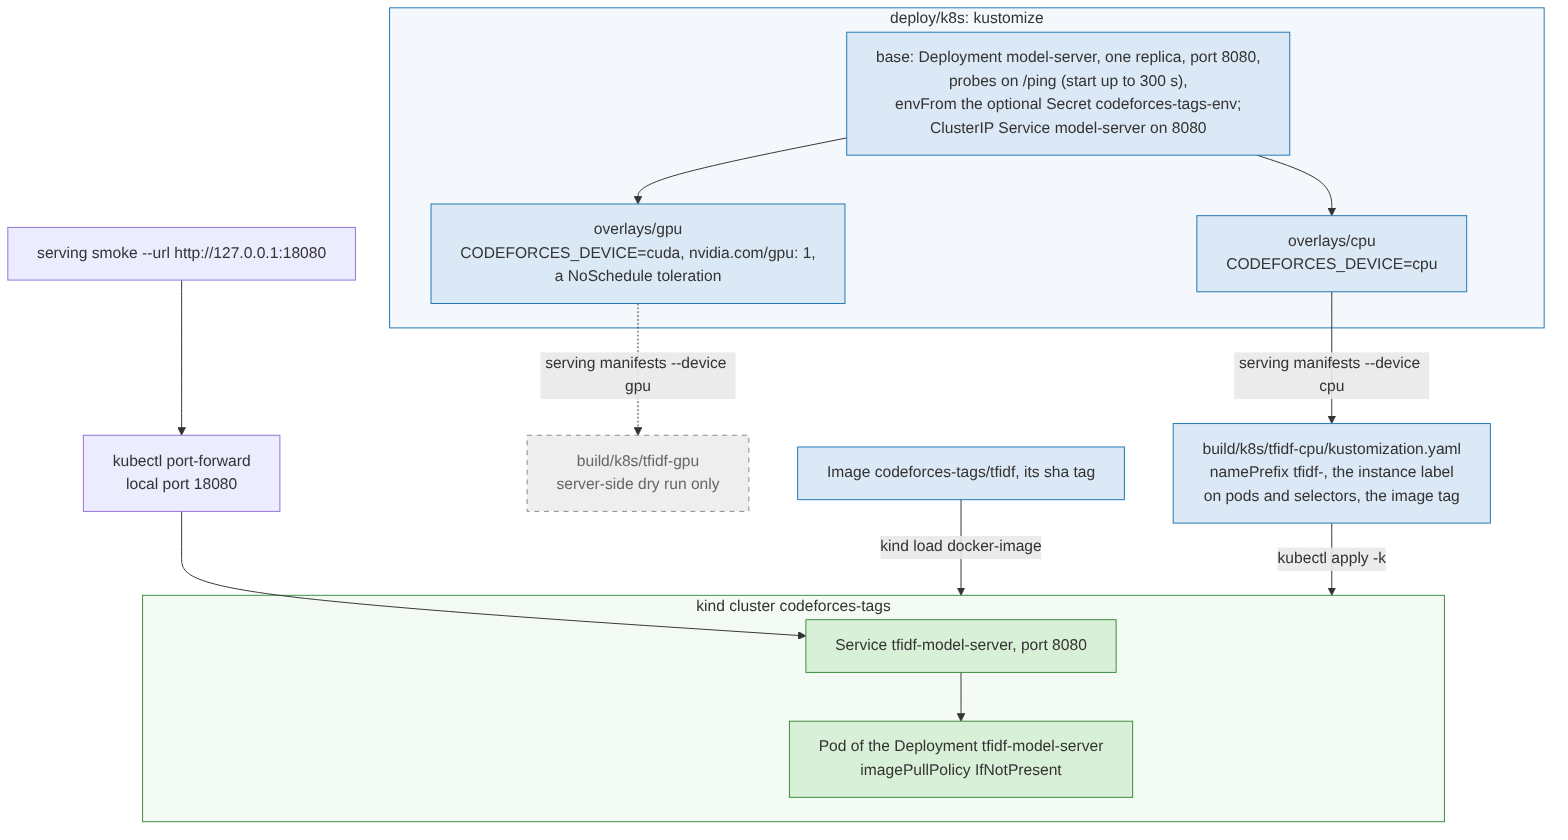

In [23]:
Image(filename="figures/serving_kubernetes.png", width=900)

**Create the kind cluster.** Run on 2026-10-11T22:37:38Z (UTC), exit status 0, in 53 s.

```console
$ kind create cluster --name codeforces-tags --wait 120s
Creating cluster "codeforces-tags" ...
 • Ensuring node image (kindest/node:v1.21.1) 🖼  ...
 ✓ Ensuring node image (kindest/node:v1.21.1) 🖼
 • Preparing nodes 📦   ...
 ✓ Preparing nodes 📦 
 • Writing configuration 📜  ...
 ✓ Writing configuration 📜
 • Starting control-plane 🕹️  ...
 ✓ Starting control-plane 🕹️
 • Installing CNI 🔌  ...
 ✓ Installing CNI 🔌
 • Installing StorageClass 💾  ...
 ✓ Installing StorageClass 💾
 • Waiting ≤ 2m0s for control-plane = Ready ⏳  ...
 ✓ Waiting ≤ 2m0s for control-plane = Ready ⏳
 • Ready after 20s 💚
Set kubectl context to "kind-codeforces-tags"
You can now use your cluster with:

kubectl cluster-info --context kind-codeforces-tags

Not sure what to do next? 😅  Check out https://kind.sigs.k8s.io/docs/user/quick-start/
```

**Load the tfidf image into the node.** Run on 2026-10-11T22:38:40Z (UTC), exit status 0, in 42 s.

```console
$ kind load docker-image codeforces-tags/tfidf:1029973 --name codeforces-tags
Image: "codeforces-tags/tfidf:1029973" with ID "sha256:8af058113b1844c65dc7e680410156185e22ff898db0357d0f1c396a2777336a" not yet present on node "codeforces-tags-control-plane", loading...
```

**The overlay for the CPU, and what it renders.** Run on 2026-10-11T22:39:36Z (UTC), exit status 0, in 3 s.

```console
$ uv run --offline python -m codeforces_tags.serving manifests --method tfidf --device cpu --tag 1029973 && cat build/k8s/tfidf-cpu/kustomization.yaml && kubectl kustomize build/k8s/tfidf-cpu
wrote <repo>/build/k8s/tfidf-cpu/kustomization.yaml: kubectl apply -k <repo>/build/k8s/tfidf-cpu
# Written by `python -m codeforces_tags.serving manifests`: write it again rather than edit it.
apiVersion: kustomize.config.k8s.io/v1beta1
kind: Kustomization
resources:
- ../../../deploy/k8s/overlays/cpu
namePrefix: tfidf-
labels:
- pairs:
    app.kubernetes.io/instance: 'tfidf'
  includeSelectors: true
[... 52 lines left out; the whole record is in docs/serving-runs.md ...]
            path: /ping
            port: 8080
          periodSeconds: 30
          timeoutSeconds: 5
        name: model-server
        ports:
        - containerPort: 8080
        readinessProbe:
          httpGet:
            path: /ping
            port: 8080
          periodSeconds: 10
        resources:
          limits:
            memory: 8Gi
          requests:
            cpu: "1"
            memory: 4Gi
        startupProbe:
          failureThreshold: 30
          httpGet:
            path: /ping
            port: 8080
          periodSeconds: 10
```

**Apply the CPU overlay.** Run on 2026-10-11T22:39:45Z (UTC), exit status 0, in 1 s.

```console
$ kubectl --context kind-codeforces-tags apply -k build/k8s/tfidf-cpu
service/tfidf-model-server created
deployment.apps/tfidf-model-server created
```

**Wait for the rollout.** Run on 2026-10-11T22:39:46Z (UTC), exit status 0, in 30 s.

```console
$ kubectl --context kind-codeforces-tags rollout status deployment/tfidf-model-server --timeout=300s
Waiting for deployment "tfidf-model-server" rollout to finish: 0 of 1 updated replicas are available...
deployment "tfidf-model-server" successfully rolled out
```

**The Deployment, its pod and the Service.** Run on 2026-10-11T22:40:16Z (UTC), exit status 0, in 0 s.

```console
$ kubectl --context kind-codeforces-tags get deployment,pods,service -o wide
NAME                                 READY   UP-TO-DATE   AVAILABLE   AGE   CONTAINERS     IMAGES                          SELECTOR
deployment.apps/tfidf-model-server   1/1     1            1           30s   model-server   codeforces-tags/tfidf:1029973   app.kubernetes.io/instance=tfidf,app.kubernetes.io/name=model-server

NAME                                      READY   STATUS    RESTARTS   AGE   IP           NODE                            NOMINATED NODE   READINESS GATES
pod/tfidf-model-server-5849cdb9dd-995j9   1/1     Running   0          30s   10.244.0.5   codeforces-tags-control-plane   <none>           <none>

NAME                         TYPE        CLUSTER-IP      EXTERNAL-IP   PORT(S)    AGE    SELECTOR
service/kubernetes           ClusterIP   10.96.0.1       <none>        443/TCP    2m8s   <none>
service/tfidf-model-server   ClusterIP   10.96.104.196   <none>        8080/TCP   30s    app.kubernetes.io/instance=tfidf,app.kubernetes.io/name=model-server
```

**Smoke: tfidf on kind, through port-forward on local port 18080.** Run on 2026-10-11T22:40:26Z (UTC), exit status 0, in 6 s.

```console
$ uv run --offline python -m codeforces_tags.serving smoke --url http://127.0.0.1:18080 --method tfidf
problem 13: 0.086 s, math: agrees
problem 14: 0.039 s, geometry: agrees
problem 15: 0.029 s, no tag: agrees
problem 18: 0.028 s, no tag: agrees
problem 29: 0.025 s, graphs: agrees
problem 37: 0.034 s, no tag: agrees
problem 39: 0.028 s, no tag: agrees
problem 60: 0.023 s, no tag: agrees
problem 62: 0.024 s, no tag: agrees
problem 64: 0.022 s, graphs: agrees
problem 68: 0.028 s, math: agrees
problem 69: 0.024 s, no tag: agrees
problem 71: 0.022 s, no tag: agrees
problem 74: 0.025 s, math: agrees
problem 75: 0.021 s, no tag: agrees
problem 79: 0.025 s, graphs: agrees
problem 89: 0.022 s, math: agrees
problem 95: 0.021 s, math, probabilities: agrees
problem 99: 0.024 s, no tag: agrees
problem 107: 0.020 s, strings, games: agrees
20 test problems, one request each: median 0.024 s, slowest 0.086 s; 0 differ from their frozen test rows
```

**The overlay for the GPU: what it adds.** Run on 2026-10-11T22:40:44Z (UTC), exit status 0, in 3 s.

```console
$ uv run --offline python -m codeforces_tags.serving manifests --method tfidf --device gpu --tag 1029973 && kubectl kustomize build/k8s/tfidf-gpu | grep -n -E 'CODEFORCES_DEVICE|value: cuda|nvidia.com/gpu|NoSchedule|image:'
wrote <repo>/build/k8s/tfidf-gpu/kustomization.yaml: kubectl apply -k <repo>/build/k8s/tfidf-gpu
39:        - name: CODEFORCES_DEVICE
40:          value: cuda
45:        image: codeforces-tags/tfidf:1029973
64:            nvidia.com/gpu: 1
75:      - effect: NoSchedule
76:        key: nvidia.com/gpu
```

**The GPU overlay, server-side dry run.** Run on 2026-10-11T22:40:47Z (UTC), exit status 0, in 1 s.

```console
$ kubectl --context kind-codeforces-tags apply -k build/k8s/tfidf-gpu --dry-run=server
service/tfidf-model-server unchanged (server dry run)
deployment.apps/tfidf-model-server configured (server dry run)
```

**Delete the cluster.** Run on 2026-10-11T22:40:53Z (UTC), exit status 0, in 2 s.

```console
$ kind delete cluster --name codeforces-tags
Deleting cluster "codeforces-tags" ...
```

## 12. SageMaker (recorded)

SageMaker runs a model's image with the argument `serve`, then sends `GET /ping` and
`POST /invocations` on port 8080: MLflow's entrypoint answers both, and ignores the argument. The
scripts of `deploy/sagemaker/` push the image to ECR and create the model, its endpoint
configuration and the endpoint (`deploy.sh`), invoke it (`invoke.sh`) and delete all three
(`delete.sh`). They were not run: they push about 8 GB and the endpoint bills by the hour, so they
run only on the user's explicit go. The container contract was checked on this machine instead,
with `docker run ... serve` and `serving smoke`, on the CPU: `/ping` answered 200 and a path that
nginx does not serve 404, and the 20 answers all agree with the frozen test rows (median 3.60 s,
slowest 8.00 s). A method that calls an API is refused by the scripts: a SageMaker model's
`Environment` is not for secrets.

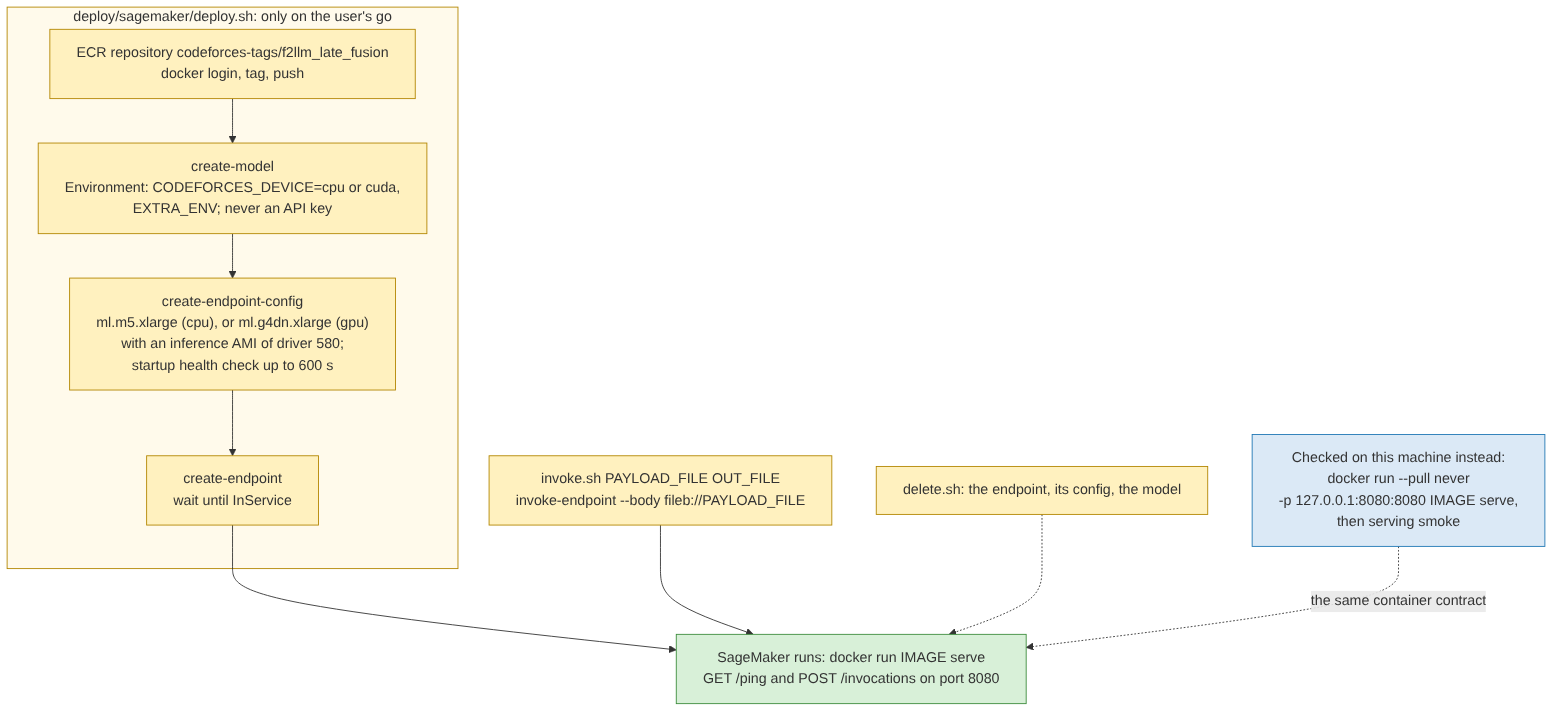

In [24]:
Image(filename="figures/serving_sagemaker.png", width=900)

**SageMaker's contract, run locally: docker run with the argument serve.** Run on 2026-10-11T22:32:07Z (UTC), exit status 0, in 1 s.

```console
$ docker run -d --rm --name codeforces-tags-serve --pull never -p 127.0.0.1:8080:8080 codeforces-tags/f2llm_late_fusion:1029973 serve
93a87a0c3945d8efcb0607869a5334c69a9210a9f1f775311707d2d8be866bc3
```

**/ping, and a path that nginx does not serve.** Run on 2026-10-11T22:32:29Z (UTC), exit status 0, in 0 s.

```console
$ curl --noproxy '*' -s -o /dev/null -w '/ping %{http_code}\n' http://127.0.0.1:8080/ping && curl --noproxy '*' -s -w ' /other %{http_code}\n' http://127.0.0.1:8080/other
/ping 200
{} /other 404
```

**Smoke: f2llm_late_fusion under docker run ... serve.** Run on 2026-10-11T22:32:29Z (UTC), exit status 0, in 84 s.

```console
$ uptime && uv run --offline python -m codeforces_tags.serving smoke --url http://127.0.0.1:8080 --method f2llm_late_fusion && uptime
[uptime's line left out]
problem 13: 2.248 s, no tag: agrees
problem 14: 2.717 s, geometry: agrees
problem 15: 2.364 s, no tag: agrees
problem 18: 3.822 s, no tag: agrees
problem 29: 3.732 s, graphs: agrees
problem 37: 3.214 s, math: agrees
problem 39: 2.492 s, no tag: agrees
problem 60: 7.571 s, strings: agrees
problem 62: 5.181 s, no tag: agrees
problem 64: 3.467 s, graphs: agrees
problem 68: 3.252 s, math: agrees
problem 69: 4.308 s, no tag: agrees
problem 71: 4.741 s, no tag: agrees
problem 74: 7.995 s, no tag: agrees
problem 75: 2.383 s, no tag: agrees
problem 79: 7.407 s, graphs: agrees
problem 89: 4.734 s, math: agrees
problem 95: 4.752 s, math, probabilities: agrees
problem 99: 2.561 s, no tag: agrees
problem 107: 1.763 s, strings, games: agrees
20 test problems, one request each: median 3.600 s, slowest 7.995 s; 0 differ from their frozen test rows
[uptime's line left out]
```

`invoke.sh` sends a request of the model server, written by `request_payload`, as the bytes of
a file (`fileb://`: AWS CLI v2 would base64-decode a `file://` body):

In [25]:
print((PROJECT_ROOT / "deploy" / "sagemaker" / "invoke.sh").read_text(encoding="utf-8"))

#!/usr/bin/env bash
# Ask the SageMaker endpoint that deploy.sh created about the problems of a payload file, and
# print its answer (docs/adr/0012). Each request is billed.
#
#   METHOD=f2llm_late_fusion DEVICE=gpu AWS_REGION=eu-west-1 \
#     deploy/sagemaker/invoke.sh payload.json answer.json
#
# The payload is a request of the model server: a dataframe_split of the raw input columns, as
# codeforces_tags.serving.client.request_payload makes it. fileb:// sends the file's bytes as they
# are: AWS CLI v2 would base64-decode a file:// body.
set -euf -o pipefail
export AWS_PAGER="" # no pager: aws CLI v2 would wait for q when $LESS lacks F

fail() {
  echo "invoke.sh: $*" >&2
  exit 1
}

(($# == 2)) || fail "usage: invoke.sh PAYLOAD_FILE OUT_FILE"
: "${METHOD:?set METHOD to the method deploy.sh deployed}"
: "${DEVICE:?set DEVICE to cpu or gpu, as for deploy.sh}"
: "${AWS_REGION:?set AWS_REGION, as for deploy.sh}"
[[ $DEVICE == cpu || $DEVICE == gpu ]] || fail "DEVICE must be cpu or gpu,

## 13. The Streamlit client

`apps/streamlit_app.py` runs on the user's machine against any of these model servers
(`uv run --group app streamlit run apps/streamlit_app.py`): it asks about a test-set problem,
beside its true focus tags and the frozen prediction of the served method, or about a problem
typed into its form. Its sidebar links the served method to what MLflow tracked about it: the
`tag-methods` experiment, the method's run (its dev out-of-fold metrics and frozen latencies, and
its logged model, which holds the run record's parameters and the test metrics) and, for a
prompted or Jev method, the prompt versions its run record pins, then those linked to its run in
the store (the Jev methods' `jev-tags`), in the MLflow UI that
`uv run python -m codeforces_tags.serving mlflow-ui` serves from the project's store. The cell
asks that UI for the links of the served method and of `descode2tag-json`, a prompted method, as
the app does.

In [26]:
ui = mlflow_ui_url()
if ui_alive(ui):
    links = {name: method_links(ui, name) for name in (METHOD, "descode2tag-json")}
    display(
        pd.DataFrame(
            {
                name: {
                    "experiment": found.experiment or "not logged in this store",
                    "run": found.run or "not logged in this store",
                    "prompt versions": "; ".join(f"{label}: {url}" for label, url in found.prompts)
                    or "none pinned",
                    "prompt registry": found.registry,
                }
                for name, found in links.items()
            }
        )
    )
else:
    print(
        f"No MLflow UI answers {ui}: start it with "
        "uv run python -m codeforces_tags.serving mlflow-ui"
    )

No MLflow UI answers http://127.0.0.1:5000: start it with uv run python -m codeforces_tags.serving mlflow-ui


The two screenshots were taken by `notebooks/figures/streamlit_app.py`. The app was served against
a local model server of `f2llm_late_fusion` on the CPU (`serving.local`, on port 18081) and the
store's MLflow UI (on port 15000), so each round trip it shows is a CPU one. The first is problem
14 of the test set, chosen by a fixed rule that never looks at a prediction: the first problem, in
the picker's order, with at least one true focus tag. Its true focus tag is strings, and the
method predicts geometry, as its frozen test row does. The second is the typed problem of
section 7, without its sample pairs.

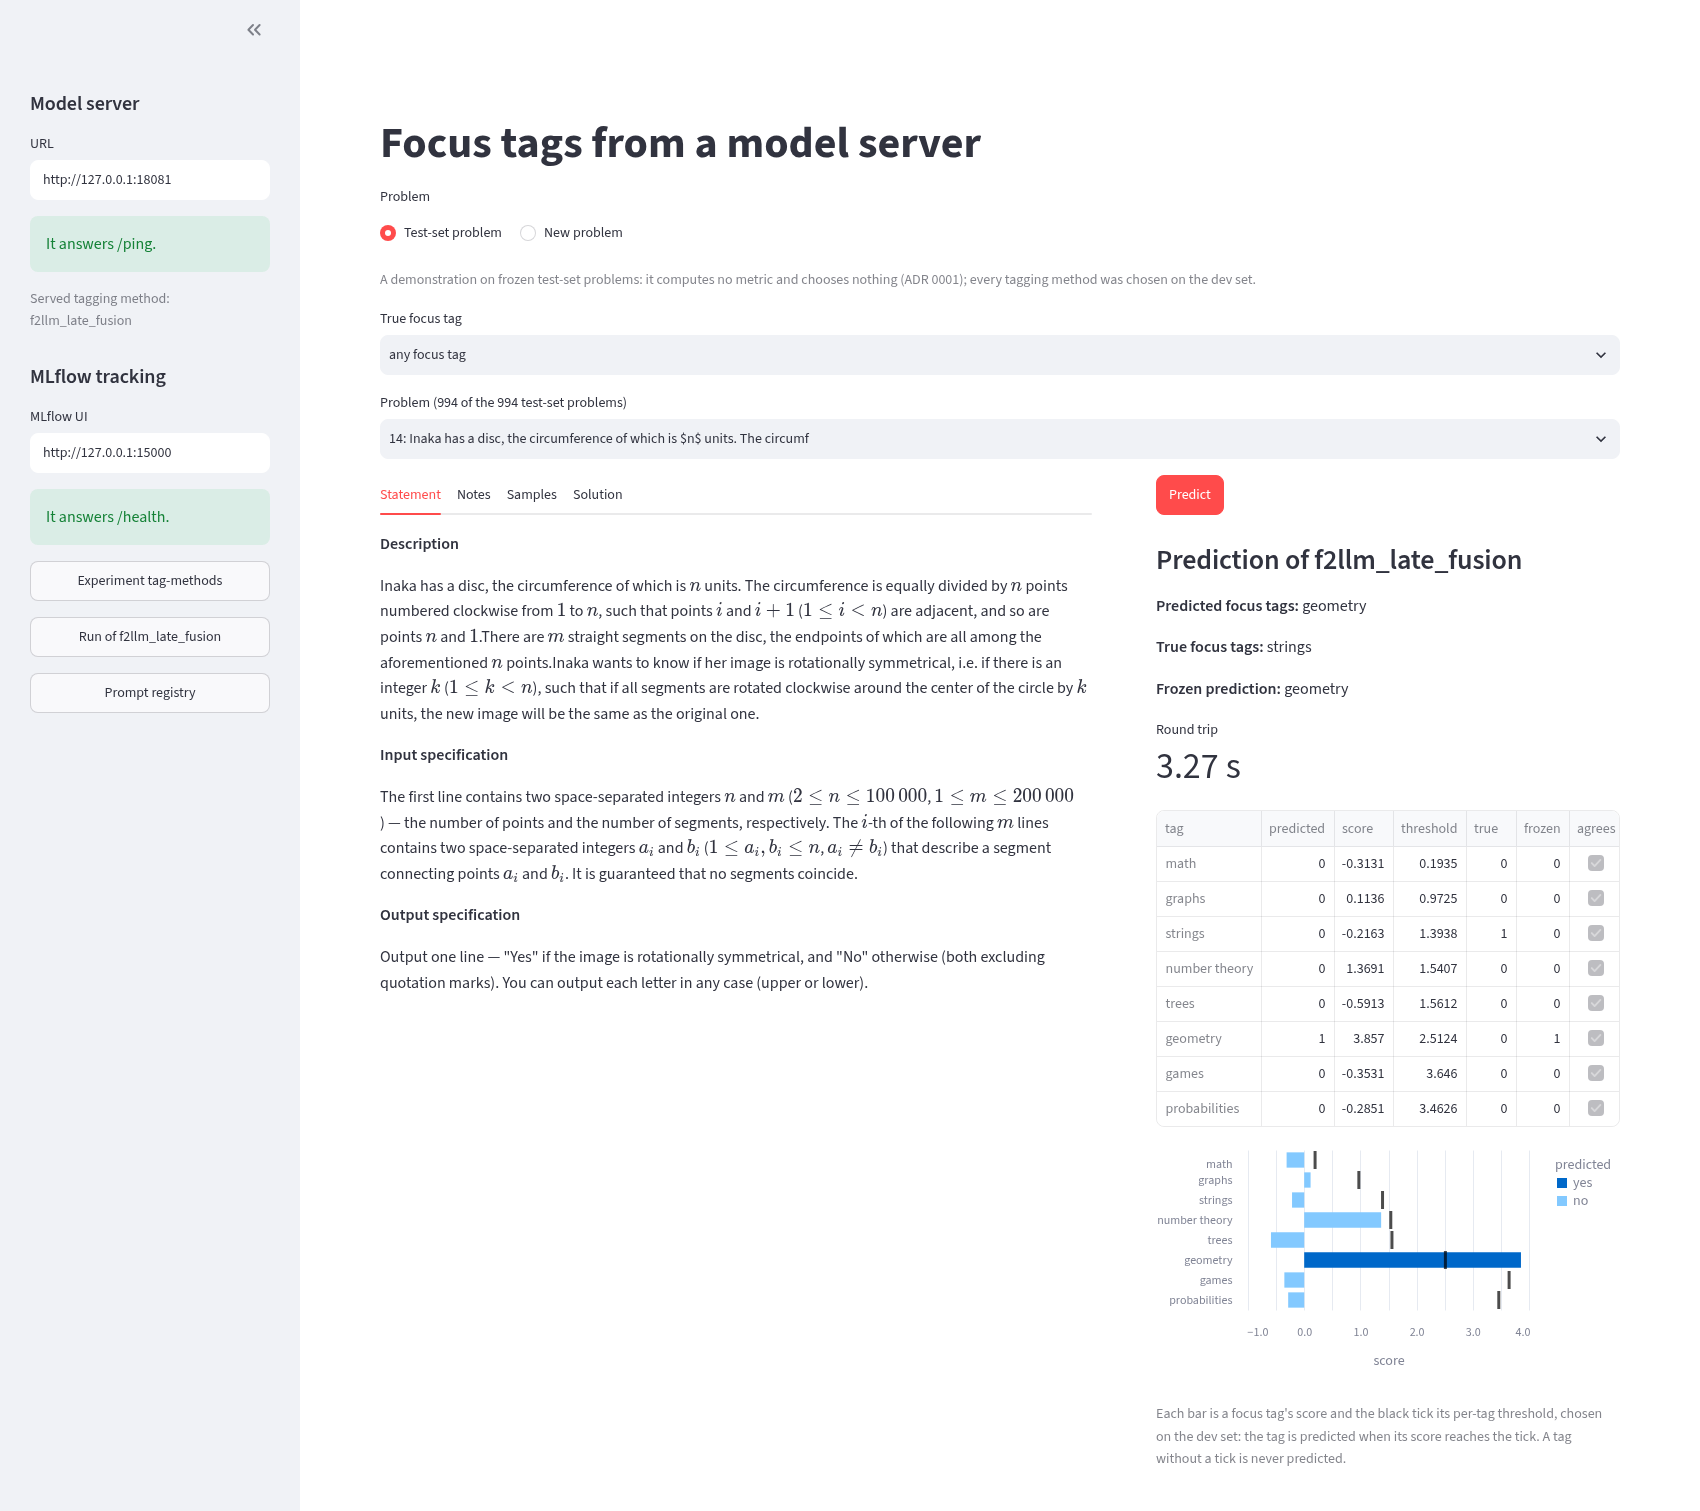

In [27]:
Image(filename="figures/streamlit/test_problem.png", width=1200)

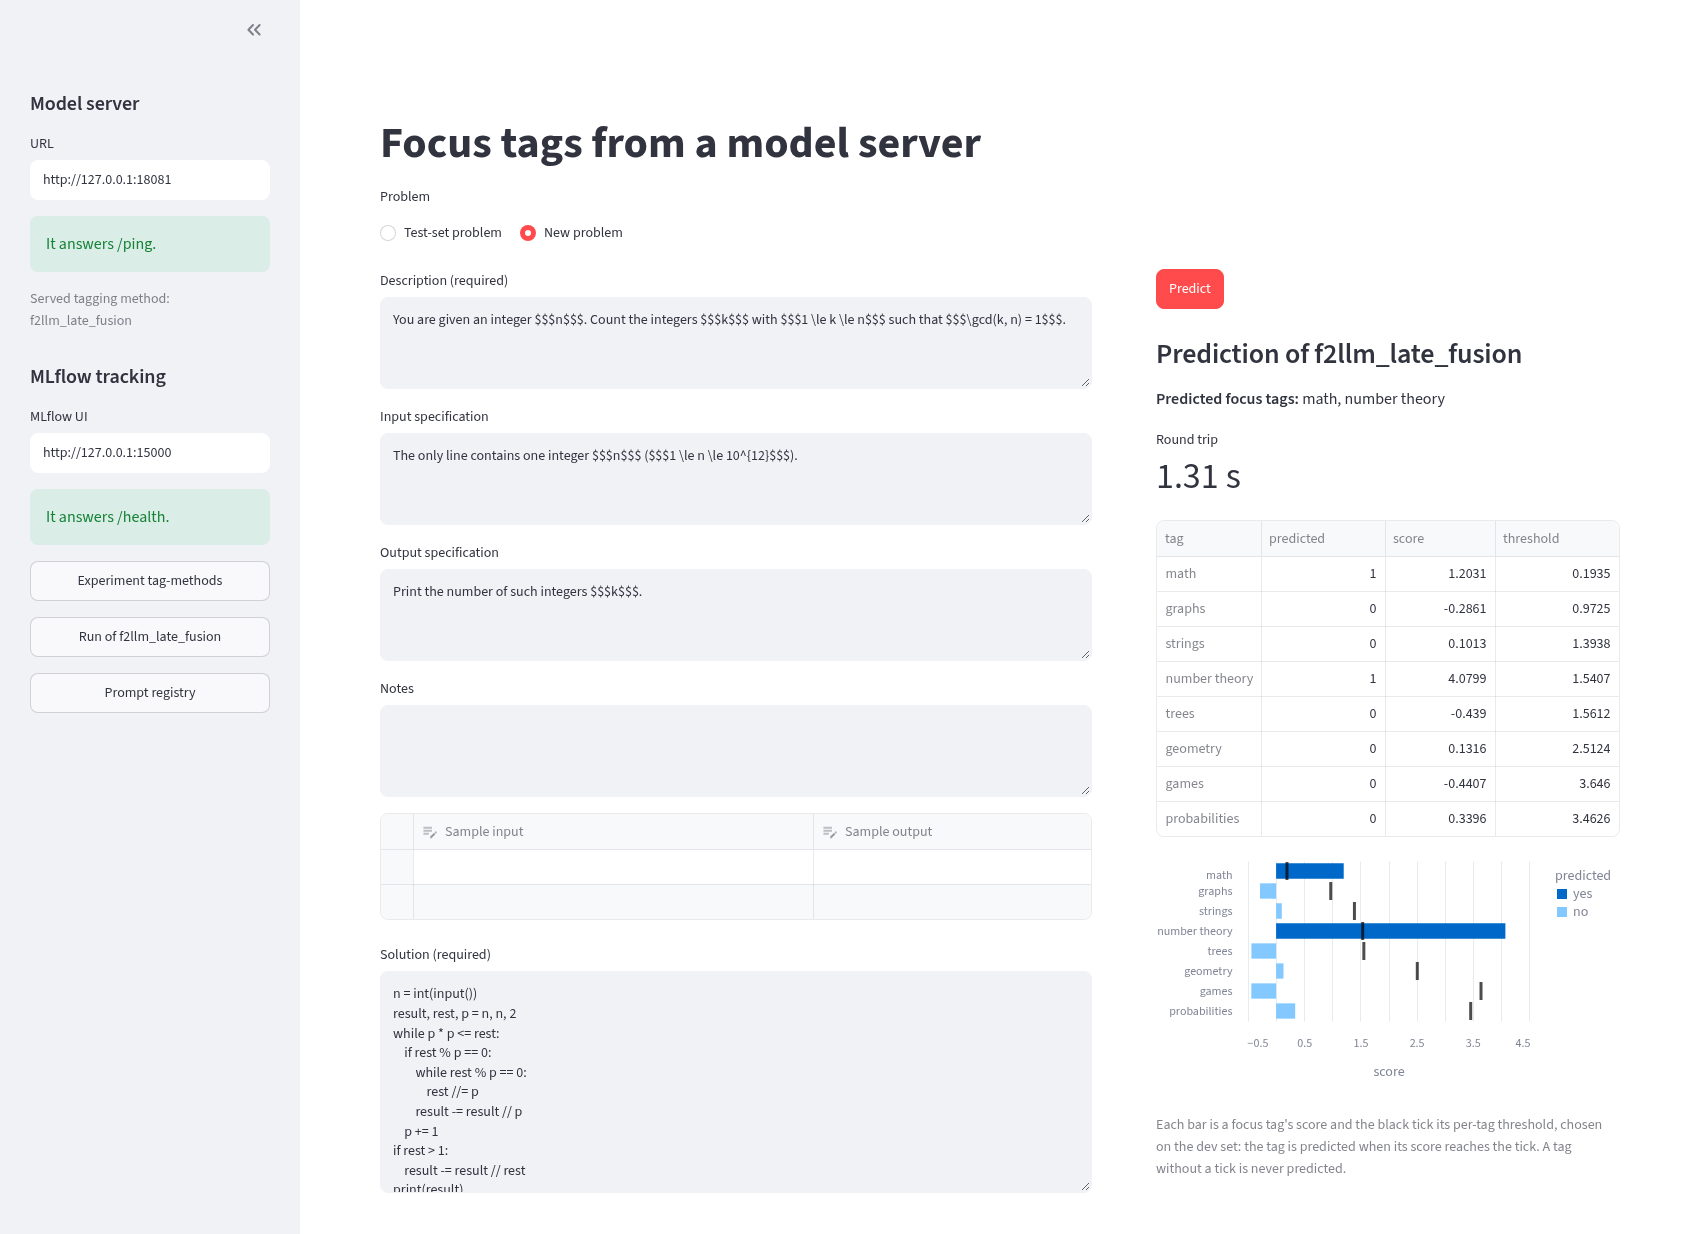

In [28]:
Image(filename="figures/streamlit/new_problem.png", width=1200)

## 14. Next steps

- **Paced GPU requests.** `serving smoke` sends its requests back to back, which drew up to
  252 W on the GPU (section 10), close to the card's 260 W limit; a pause between requests would
  keep a long series well below it.
- **A GPU cluster.** Push the image to a registry (`manifests --registry R`) and run the `gpu`
  overlay on nodes with NVIDIA's device plugin and a driver of 580 or later; here the GPU overlay
  was only checked by a server-side dry run.
- **SageMaker.** Run `deploy/sagemaker/deploy.sh`, on the user's go and with a newer aws CLI for
  the GPU path (`InferenceAmiVersion`), then measure the endpoint's latency with `invoke.sh`.
- **In front of the server.** Authentication and TLS: today compose publishes on 127.0.0.1 only,
  Kubernetes behind a ClusterIP Service, SageMaker behind IAM.
- **Throughput.** One worker and a lock serve one prediction at a time; batching the requests of
  several clients, or autoscaling replicas, would serve more at once.
- **Monitoring.** Log each request's latency and the served method's version, for instance as
  MLflow traces, which the model server does not write today.
- **A smaller CPU image.** A CPU-only torch would shrink the late-fusion image, at the cost of a
  second lock that departs from `uv.lock`'s pins.
- **An API method.** Serve the command line's default, `jev-statement-code`, with its key from a
  Kubernetes Secret or `deploy/.env.serving`: one problem per request, each answer's cost in
  `cost_usd`.